<a href="https://colab.research.google.com/github/yimarbriceon/ingenieria-conocimiento-uncp/blob/master/parcial_Actividad2_CNN_EuroSAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 2 — Red Neuronal Convolucional sobre Dataset de Imagen Real

## SECCIÓN A — Presentación

| Campo | Detalle |
|---|---|
| **Curso** | Ingeniería del Conocimiento (ISO56B) |
| **Semestre** | 2026-II |
| **Fecha** | _[dd/mm/aaaa]_ |
| **Docente** | Msc. Jaime Antonio Huaytalla Pariona |
| **Universidad** | Universidad Nacional del Centro del Perú — Facultad de Ingeniería de Sistemas |

**Integrantes**

| N° | Apellidos y nombres | Código |
|---|---|---|
| 1 | _[Integrante 1]_ | _[Código]_ |
| 2 | _[Integrante 2]_ | _[Código]_ |
| 3 | _[Integrante 3]_ | _[Código]_ |
| 4 | _[Integrante 4]_ | _[Código]_ |

**Dataset elegido:** EuroSAT (versión RGB) — 27 000 imágenes satelitales reales de 64×64 píxeles tomadas por el satélite **Sentinel-2** del programa europeo Copernicus, etiquetadas en **10 clases de uso y cobertura de suelo**:

| Clase (TFDS) | Nombre en español |
|---|---|
| AnnualCrop | Cultivo anual |
| Forest | Bosque |
| HerbaceousVegetation | Vegetación herbácea |
| Highway | Autopista |
| Industrial | Zona industrial |
| Pasture | Pastizal |
| PermanentCrop | Cultivo permanente |
| Residential | Residencial |
| River | Río |
| SeaLake | Lago o mar |

**Fuente:**
- Zenodo (registro oficial de los autores, de donde se descarga en B.2): https://zenodo.org/records/7711810
- TensorFlow Datasets (el mismo dataset como `eurosat/rgb`): https://www.tensorflow.org/datasets/catalog/eurosat
- Repositorio original: https://github.com/phelber/EuroSAT
- Artículo: Helber, P., Bischke, B., Dengel, A. y Borth, D. (2019). *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*. IEEE JSTARS, 12(7), 2217–2226.

**Justificación de la elección**
- Cumple todos los requisitos mínimos: es de **clasificación de imágenes**, tiene **27 000 imágenes** (muy por encima de 1 000), **10 clases** (más de 3) y son **imágenes reales** captadas por un satélite, no generadas sintéticamente.
- No es MNIST ni Fashion-MNIST y no se usó en las sesiones del curso ni en los laboratorios.
- Tiene aplicación real directa: el monitoreo del uso de suelo sirve para planificación urbana, control de deforestación, agricultura y gestión de recursos hídricos.
- Las imágenes de 64×64 píxeles permiten entrenar varias CNN desde cero en una GPU T4 dentro de una sesión de Colab, y el volumen de datos es suficiente para que la red aprenda sin transfer learning.

**Descripción del problema**
Dada una imagen satelital RGB de 64×64 píxeles (cada píxel cubre unos 10 m de terreno, es decir, un recorte de unos 640 × 640 m), el modelo debe predecir a cuál de las 10 clases de uso de suelo pertenece. Es un problema de **clasificación multiclase** con clases mutuamente excluyentes. La dificultad está en que varias clases se parecen mucho vistas desde arriba: cultivos anuales, cultivos permanentes, pastizales y vegetación herbácea son todos “parches verdes o marrones”; autopistas y ríos son líneas que cruzan la imagen; zonas industriales y residenciales son texturas de edificaciones. Se entrenará una CNN base, una CNN mejorada con regularización y se compararán optimizadores, evaluando todo sobre un conjunto de prueba que el modelo nunca vio.

**Entorno de ejecución:** este notebook se ejecutó con **GPU habilitada** (Runtime → Change runtime type → **T4 GPU**). La celda B.1 imprime la GPU detectada como evidencia.

## SECCIÓN B — Carga, Exploración y Preprocesamiento

### B.1 Librerías, semilla y verificación de GPU
**Qué hace este bloque:**
- Importa las librerías: `numpy`/`pandas` para manejar datos, `matplotlib`/`seaborn` para gráficos, `tensorflow.keras` para construir la CNN y `scikit-learn` para el split estratificado y las métricas.
- Fija una **semilla** (`SEED = 42`) en Python, NumPy y TensorFlow para que los resultados sean reproducibles (misma división de datos y misma inicialización de pesos).
- Verifica si hay GPU. Si aparece “NO”, hay que activar la T4 en *Runtime → Change runtime type*.
- Define en un solo lugar los hiperparámetros globales: tamaño de imagen (64×64, la resolución nativa de EuroSAT), tamaño de lote y número de épocas de cada experimento.

In [4]:
# ---------------- Librerías ----------------
import os, random, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# ---------------- Reproducibilidad ----------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# ---------------- Verificación de GPU ----------------
print("Versión de TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print("GPU detectada:", gpus)
else:
    print("NO se detectó GPU -> Runtime > Change runtime type > T4 GPU")

# ---------------- Hiperparámetros globales ----------------
IMG_SIZE        = 64    # resolución nativa de EuroSAT (64x64), no se redimensiona
BATCH_SIZE      = 32
EPOCHS_BASE     = 20    # la consigna pide 15-20 épocas para la CNN base
EPOCHS_MEJORADA = 40    # máximo; EarlyStopping la detendrá antes si deja de mejorar
EPOCHS_OPT      = 15    # épocas por optimizador en la Sección E

plt.rcParams['figure.dpi'] = 100

Versión de TensorFlow: 2.21.0
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### B.2 Descarga del dataset desde Zenodo
**Qué hace este bloque:**
- Descarga `EuroSAT_RGB.zip` (≈90 MB) desde **Zenodo**, el repositorio oficial donde los autores publicaron EuroSAT (registro 7711810). Es exactamente el mismo dataset que ofrece `tfds.load('eurosat/rgb')`; se usa Zenodo porque el servidor que usa TensorFlow Datasets suele estar saturado.
- Se envía un encabezado `User-Agent` de navegador porque algunos servidores rechazan descargas sin él.
- **Plan de respaldo:** si la descarga falla, busca el archivo `EuroSAT_RGB.zip` subido a mano al panel de archivos de Colab (o la carpeta ya extraída de una ejecución anterior).
- Descomprime el zip y localiza automáticamente la carpeta que contiene las 10 subcarpetas de clases (la que contiene `AnnualCrop`). El dataset está organizado como **una carpeta por clase**, por lo que el nombre de la carpeta es la etiqueta.

In [5]:
import os
import zipfile
import urllib.request
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import image_dataset_from_directory

# Rutas de trabajo y URL oficial de Zenodo con parámetro de descarga directa
zip_path = "EuroSAT_RGB.zip"
extract_path = "eurosat_data"
url_zenodo = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"

descarga_exitosa = False

print("Intentando descargar el dataset EuroSAT por URL (desde Zenodo)...")
try:
    # Usamos urlretrieve que maneja automáticamente redirecciones y flujos grandes
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    req = urllib.request.Request(url_zenodo, headers=headers)

    with urllib.request.urlopen(req) as response, open(zip_path, 'wb') as out_file:
        out_file.write(response.read())

    print("¡Descarga por URL exitosa! Descomprimiendo archivos...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    descarga_exitosa = True
    print("Dataset extraído correctamente.")

except Exception as e:
    print(f"\n[AVISO]: La descarga por URL falló debido a la red: {e}")
    print("Activando PLAN DE RESPALDO: Buscando archivo local en el disco de Colab...")

# PLAN DE RESPALDO: Si la red falla, revisa si el archivo fue subido manualmente al entorno
if not descarga_exitosa:
    if os.path.exists(zip_path):
        print("¡Archivo 'EuroSAT_RGB.zip' encontrado localmente! Descomprimiendo...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_path)
        descarga_exitosa = True
    elif os.path.exists(extract_path):
        print("¡Carpeta 'eurosat_data' ya existente en el disco local!")
        descarga_exitosa = True
    else:
        raise FileNotFoundError(
            "ERROR CRÍTICO: La descarga falló y no se encontró 'EuroSAT_RGB.zip' en el entorno. "
            "Sube el archivo comprimido manualmente a la pestaña de archivos (icono de carpeta a la izquierda en Colab)."
        )

# Localizar dinámicamente la carpeta que contiene las clases dentro de la extracción
import glob
subcarpetas = [p for p in glob.glob(os.path.join(extract_path, "**"), recursive=True) if os.path.isdir(p) and "AnnualCrop" in os.listdir(p)]
if subcarpetas:
    data_dir = subcarpetas[0]
else:
    candidatos = [os.path.join(extract_path, d) for d in os.listdir(extract_path) if os.path.isdir(os.path.join(extract_path, d))]
    data_dir = candidatos[0] if candidatos else extract_path

print(f"Directorio de datos listo en: {data_dir}")

# Carga de imágenes a memoria y estructuración en X e y (para mantener compatibilidad con la Sección B.3)
print("Cargando imágenes en arreglos NumPy...")
dataset_keras = image_dataset_from_directory(
    data_dir,
    image_size=(64, 64),
    batch_size=32,
    shuffle=False,
    label_mode='int'
)

CLASES_EN = dataset_keras.class_names
TRADUCCION = {
    "AnnualCrop": "Cultivo anual",       "Forest": "Bosque",
    "HerbaceousVegetation": "Veg. herbácea", "Highway": "Autopista",
    "Industrial": "Industrial",          "Pasture": "Pastizal",
    "PermanentCrop": "Cultivo perm.",    "Residential": "Residencial",
    "River": "Río",                      "SeaLake": "Lago/mar",
}
CLASES = [TRADUCCION.get(c, c) for c in CLASES_EN]
NUM_CLASES = len(CLASES)

X_lotes, y_lotes = [], []
for imgs, etiquetas in dataset_keras:
    X_lotes.append(imgs.numpy())
    y_lotes.append(etiquetas.numpy())

X = np.concatenate(X_lotes)
y = np.concatenate(y_lotes).astype(np.int64)
del X_lotes, y_lotes

print(f"\n¡Proceso completado con éxito!")
print("Forma de X:", X.shape, "| tipo:", X.dtype)
print("Forma de y:", y.shape, "| etiquetas únicas:", np.unique(y))
print("Número de clases:", NUM_CLASES)

Intentando descargar el dataset EuroSAT por URL (desde Zenodo)...
¡Descarga por URL exitosa! Descomprimiendo archivos...
Dataset extraído correctamente.
Directorio de datos listo en: eurosat_data/EuroSAT_RGB
Cargando imágenes en arreglos NumPy...
Found 27000 files belonging to 10 classes.

¡Proceso completado con éxito!
Forma de X: (27000, 64, 64, 3) | tipo: float32
Forma de y: (27000,) | etiquetas únicas: [0 1 2 3 4 5 6 7 8 9]
Número de clases: 10


In [6]:
import zipfile, glob, urllib.request

zip_path     = "EuroSAT_RGB.zip"
extract_path = "eurosat_data"
url_zenodo   = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"

def carpeta_de_clases(raiz):
    # Devuelve la carpeta que contiene las subcarpetas de clases (la que tiene 'AnnualCrop')
    for p in glob.glob(os.path.join(raiz, "**"), recursive=True):
        if os.path.isdir(p) and "AnnualCrop" in os.listdir(p):
            return p
    return None

data_dir = carpeta_de_clases(extract_path) if os.path.isdir(extract_path) else None

if data_dir is None:                                  # no está extraído todavía
    if not os.path.exists(zip_path):
        print("Descargando EuroSAT RGB desde Zenodo...")
        try:
            req = urllib.request.Request(url_zenodo, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req) as resp, open(zip_path, "wb") as f:
                f.write(resp.read())
            print("Descarga completada.")
        except Exception as e:
            if os.path.exists(zip_path):
                os.remove(zip_path)                   # borrar descarga incompleta
            raise RuntimeError(
                f"La descarga falló ({e}). Sube 'EuroSAT_RGB.zip' al panel de archivos "
                "de Colab (icono de carpeta) y vuelve a ejecutar esta celda.")
    print("Descomprimiendo...")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(extract_path)
    data_dir = carpeta_de_clases(extract_path)

CLASES_EN = sorted(d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d)))
TRADUCCION = {
    "AnnualCrop": "Cultivo anual",       "Forest": "Bosque",
    "HerbaceousVegetation": "Veg. herbácea", "Highway": "Autopista",
    "Industrial": "Industrial",          "Pasture": "Pastizal",
    "PermanentCrop": "Cultivo perm.",    "Residential": "Residencial",
    "River": "Río",                      "SeaLake": "Lago/mar",
}
CLASES = [TRADUCCION[c] for c in CLASES_EN]       # nombres cortos en español
NUM_CLASES = len(CLASES)

print("Carpeta del dataset:", data_dir)
print("Número de clases   :", NUM_CLASES)
for i, (en, es) in enumerate(zip(CLASES_EN, CLASES)):
    n = len(glob.glob(os.path.join(data_dir, en, "*.jpg")))
    print(f"  {i}: {en:<22s} -> {es:<14s} ({n} imágenes)")

Carpeta del dataset: eurosat_data/EuroSAT_RGB
Número de clases   : 10
  0: AnnualCrop             -> Cultivo anual  (3000 imágenes)
  1: Forest                 -> Bosque         (3000 imágenes)
  2: HerbaceousVegetation   -> Veg. herbácea  (3000 imágenes)
  3: Highway                -> Autopista      (2500 imágenes)
  4: Industrial             -> Industrial     (2500 imágenes)
  5: Pasture                -> Pastizal       (2000 imágenes)
  6: PermanentCrop          -> Cultivo perm.  (2500 imágenes)
  7: Residential            -> Residencial    (3000 imágenes)
  8: River                  -> Río            (2500 imágenes)
  9: SeaLake                -> Lago/mar       (3000 imágenes)


### B.3 Lectura de imágenes a arreglos NumPy
**Qué hace este bloque:**
- `image_dataset_from_directory` lee todas las imágenes de las carpetas y asigna a cada una la etiqueta de su carpeta. Las clases se numeran en **orden alfabético** (0 = AnnualCrop, …, 9 = SeaLake), el mismo orden de `CLASES_EN`.
- `shuffle=False` mantiene el orden de lectura; la mezcla se hace después en el split estratificado.
- Keras devuelve las imágenes como `float32` con valores 0–255. Como todas ya miden 64×64, no hay interpolación y los valores son enteros exactos, así que se convierten a **`uint8`** para que ocupen 4 veces menos memoria (≈330 MB en vez de ≈1,3 GB) y para que `plt.imshow` las muestre correctamente. La normalización a [0, 1] se hace después del split (B.8).
- Resultado: `X` con forma `(27000, 64, 64, 3)` y `y` con la etiqueta entera de cada imagen (0 a 9).

In [7]:
inicio = time.time()
dataset_keras = keras.utils.image_dataset_from_directory(
    data_dir,
    labels="inferred", label_mode="int",
    class_names=CLASES_EN,          # mismo orden que CLASES
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=1024,
    shuffle=False)

X_lotes, y_lotes = [], []
for imgs, etiquetas in dataset_keras:
    X_lotes.append(imgs.numpy().astype(np.uint8))   # float32 0-255 -> uint8 0-255
    y_lotes.append(etiquetas.numpy())
X = np.concatenate(X_lotes)
y = np.concatenate(y_lotes).astype(np.int64)
del X_lotes, y_lotes, dataset_keras

print(f"Lectura terminada en {time.time()-inicio:.1f} s")
print("Forma de X:", X.shape, "| tipo:", X.dtype)
print("Forma de y:", y.shape, "| etiquetas únicas:", np.unique(y))

Found 27000 files belonging to 10 classes.
Lectura terminada en 4.0 s
Forma de X: (27000, 64, 64, 3) | tipo: uint8
Forma de y: (27000,) | etiquetas únicas: [0 1 2 3 4 5 6 7 8 9]


### B.4 Dimensiones del dataset
**Qué hace este bloque:**
- Reporta el número total de imágenes, la resolución, los canales y el rango de valores de los píxeles.
- A diferencia de datasets de fotos tomadas con cámaras distintas, en EuroSAT **todas las imágenes tienen exactamente 64×64×3**, así que **no hace falta redimensionar**: se trabaja con la resolución nativa.
- También calcula la media y desviación de cada canal (R, G, B), lo que da una idea de los colores dominantes (mucho verde de vegetación y poco rojo).
- El número de imágenes de train/val/test se muestra en B.8, después del split.

In [8]:
print(f"Total de imágenes   : {len(X)}")
print(f"Número de clases    : {NUM_CLASES}")
print(f"Resolución          : {X.shape[1]}x{X.shape[2]} píxeles (todas las imágenes tienen el mismo tamaño)")
print(f"Canales             : {X.shape[3]} (RGB)")
print(f"Rango de píxeles    : [{X.min()}, {X.max()}] ({X.dtype})")
print(f"Memoria del arreglo : {X.nbytes/1e6:.0f} MB")

medias = X.reshape(-1, 3).mean(axis=0)
desv   = X.reshape(-1, 3).std(axis=0)
for canal, m, s in zip("RGB", medias, desv):
    print(f"  Canal {canal}: media = {m:6.1f}  desviación = {s:5.1f}")

Total de imágenes   : 27000
Número de clases    : 10
Resolución          : 64x64 píxeles (todas las imágenes tienen el mismo tamaño)
Canales             : 3 (RGB)
Rango de píxeles    : [0, 255] (uint8)
Memoria del arreglo : 332 MB
  Canal R: media =   86.6  desviación =  51.9
  Canal G: media =   97.0  desviación =  35.1
  Canal B: media =  102.6  desviación =  29.6


### B.5 Grilla de ejemplos (al menos 1 imagen por clase)
**Qué hace este bloque:**
- Usa `plt.subplots` para crear una grilla de 3 filas × 10 columnas: cada columna es una clase y se muestran 3 imágenes aleatorias de esa clase con su etiqueta.
- Sirve para inspeccionar la variabilidad dentro de cada clase y anticipar qué clases podrían confundirse (por ejemplo, autopista y río son ambas líneas que cruzan la imagen).

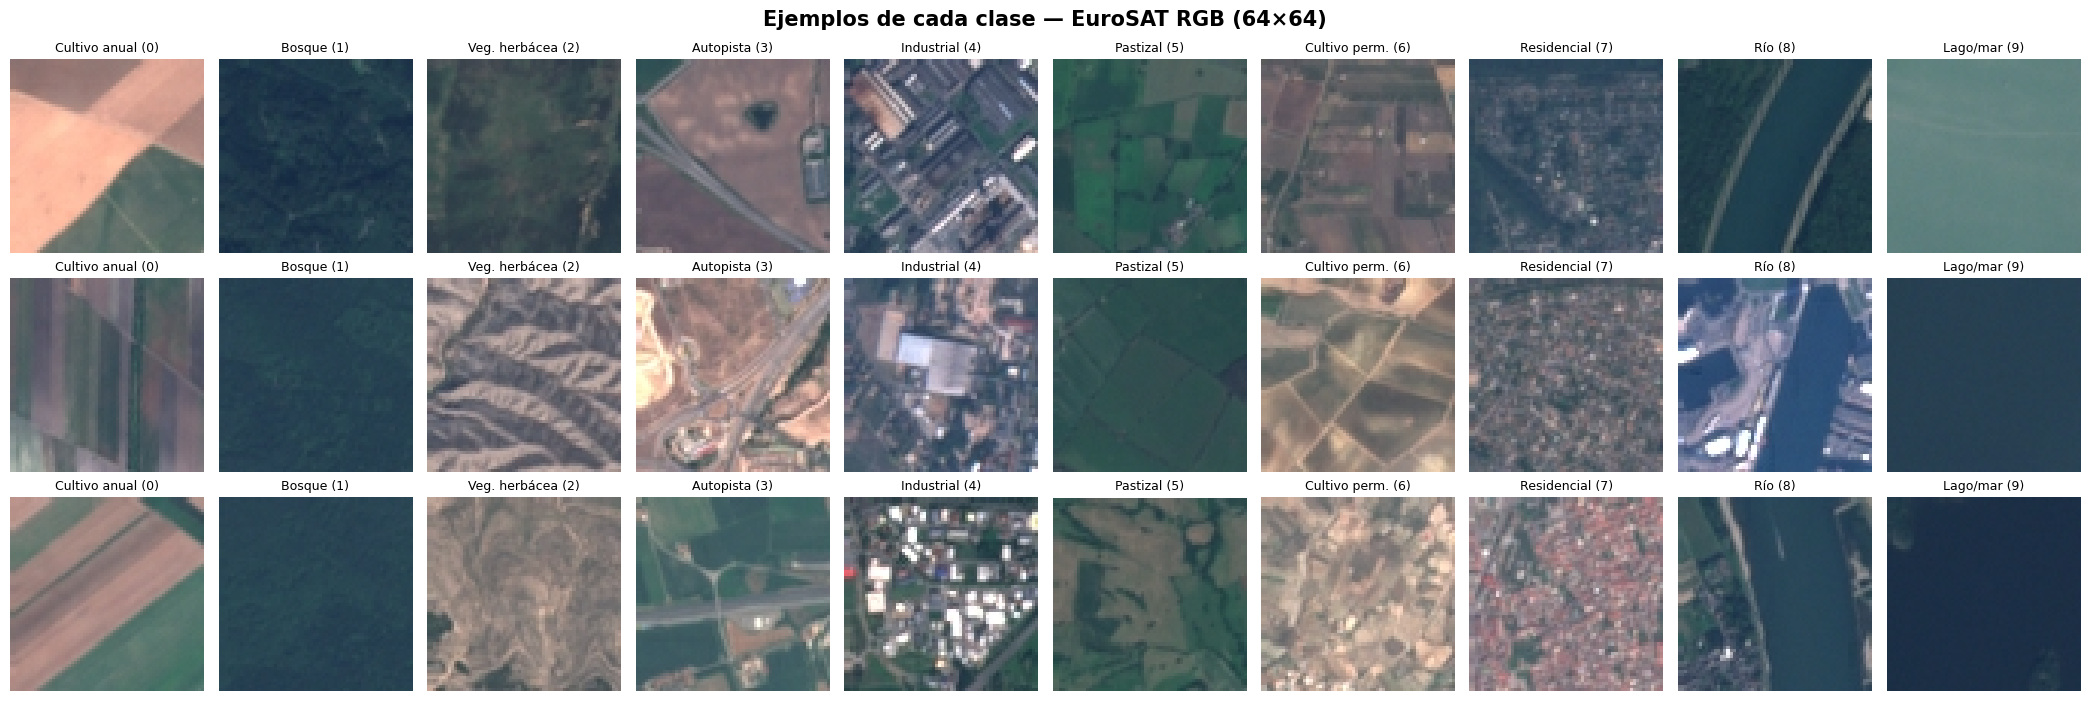

In [9]:
n_por_clase = 3
fig, axes = plt.subplots(n_por_clase, NUM_CLASES, figsize=(2.1*NUM_CLASES, 2.4*n_por_clase))
rng = np.random.default_rng(SEED)
for c, clase in enumerate(CLASES):
    indices = rng.choice(np.where(y == c)[0], n_por_clase, replace=False)
    for f, i in enumerate(indices):
        ax = axes[f, c]
        ax.imshow(X[i])
        ax.set_title(f"{clase} ({c})", fontsize=9)
        ax.axis("off")
plt.suptitle("Ejemplos de cada clase — EuroSAT RGB (64×64)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### B.6 Distribución de clases
**Qué hace este bloque:**
- Cuenta cuántas imágenes hay por clase con `np.bincount` y lo grafica en barras, anotando el conteo y el porcentaje.
- Permite ver si el dataset está **desbalanceado**. En EuroSAT las clases tienen entre 2 000 y 3 000 imágenes: el desbalance es leve, pero igual se usa estratificación en el split y se mira el F1 por clase en la evaluación.

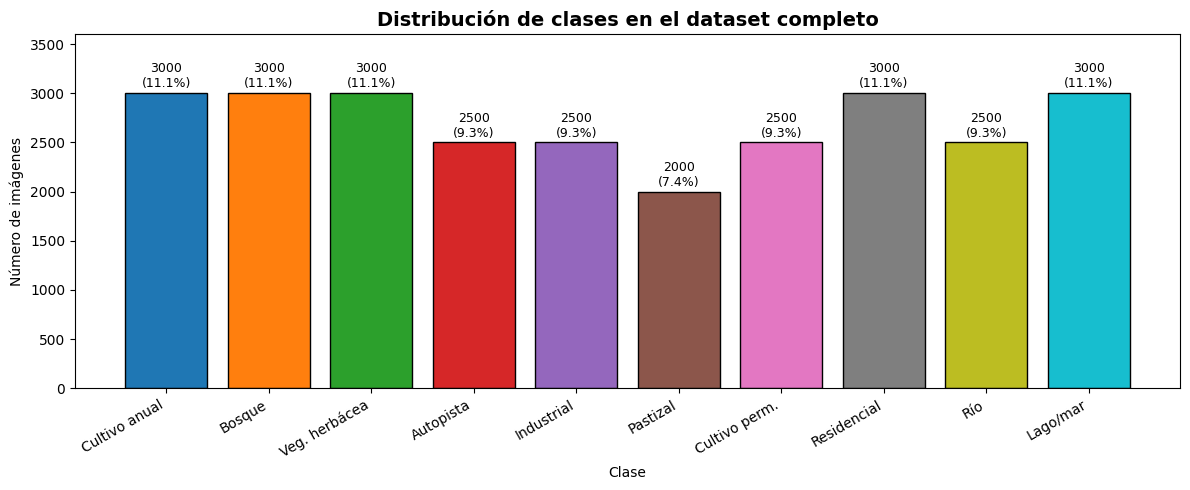

        clase  imagenes  porcentaje
Cultivo anual      3000       11.11
       Bosque      3000       11.11
Veg. herbácea      3000       11.11
    Autopista      2500        9.26
   Industrial      2500        9.26
     Pastizal      2000        7.41
Cultivo perm.      2500        9.26
  Residencial      3000       11.11
          Río      2500        9.26
     Lago/mar      3000       11.11

Razón clase mayoritaria / minoritaria: 1.50


In [10]:
conteos = np.bincount(y, minlength=NUM_CLASES)
porcentajes = conteos / conteos.sum() * 100

plt.figure(figsize=(12, 5))
barras = plt.bar(CLASES, conteos, color=sns.color_palette("tab10", NUM_CLASES), edgecolor="black")
for b, n, p in zip(barras, conteos, porcentajes):
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 30, f"{n}\n({p:.1f}%)",
             ha="center", va="bottom", fontsize=9)
plt.title("Distribución de clases en el dataset completo", fontsize=14, fontweight="bold")
plt.xlabel("Clase"); plt.ylabel("Número de imágenes")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, conteos.max() * 1.2)
plt.tight_layout(); plt.show()

print(pd.DataFrame({"clase": CLASES, "imagenes": conteos, "porcentaje": porcentajes.round(2)}).to_string(index=False))
print(f"\nRazón clase mayoritaria / minoritaria: {conteos.max()/conteos.min():.2f}")

### B.6b Color medio por clase (exploración adicional)
**Qué hace este bloque:**
- Calcula el valor medio de los canales R, G y B de todas las imágenes de cada clase y lo grafica como barras agrupadas, junto con un parche del color promedio.
- Ayuda a entender qué información de color puede usar la red: *Bosque* y *Lago/mar* son las clases más oscuras (con poco rojo), *Industrial* es la más clara, y *Cultivo anual* y *Cultivo permanente* tienen un color promedio casi idéntico, lo que anticipa que la red tendrá que distinguirlas por la **textura** (forma y tamaño de las parcelas) y no por el color. En casi todas las clases el canal azul es alto por el efecto de la atmósfera (bruma) en las imágenes satelitales.

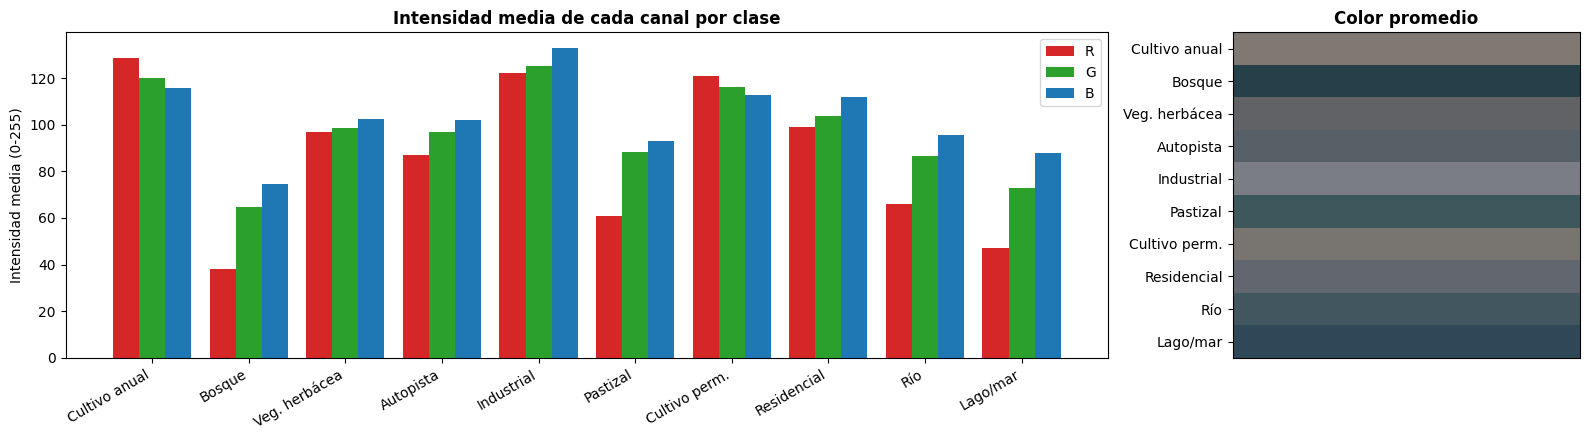

In [11]:
color_medio = np.array([X[y == c].reshape(-1, 3).mean(axis=0) for c in range(NUM_CLASES)])

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 1]})
ancho = 0.27
pos = np.arange(NUM_CLASES)
for k, (canal, col) in enumerate(zip("RGB", ["tab:red", "tab:green", "tab:blue"])):
    ax[0].bar(pos + (k-1)*ancho, color_medio[:, k], ancho, color=col, label=canal)
ax[0].set_xticks(pos); ax[0].set_xticklabels(CLASES, rotation=30, ha="right")
ax[0].set_ylabel("Intensidad media (0-255)"); ax[0].legend()
ax[0].set_title("Intensidad media de cada canal por clase", fontweight="bold")

ax[1].imshow(color_medio[:, None, :].astype(np.uint8), aspect="auto")
ax[1].set_yticks(range(NUM_CLASES)); ax[1].set_yticklabels(CLASES); ax[1].set_xticks([])
ax[1].set_title("Color promedio", fontweight="bold")
plt.tight_layout(); plt.show()

### B.7 Split estratificado: train / validación / test
**Qué hace este bloque:**
- Como EuroSAT **no trae un conjunto de test oficial**, primero se separa un **15 % como test** (estratificado). Este conjunto no se toca hasta la Sección F.
- Del 85 % restante se separa el **10 % como validación** (estratificado), tal como pide la consigna. La validación se usa para monitorear el entrenamiento, activar los callbacks y comparar modelos.
- `stratify=y` mantiene la misma proporción de cada clase en los tres conjuntos; sin estratificar, por azar una clase podría quedar sub-representada en validación o test y las métricas serían engañosas.
- `random_state=SEED` hace que la división sea siempre la misma.

In [12]:
# 1) Separar test (15 %) del total
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)

# 2) Separar validación (10 % del train) con estratificación
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.10, stratify=y_trainval, random_state=SEED)

del X_trainval, y_trainval   # liberar memoria

# Verificación de la estratificación: proporción de cada clase en cada conjunto
proporciones = pd.DataFrame({
    "train (%)": np.bincount(y_train) / len(y_train) * 100,
    "val (%)"  : np.bincount(y_val)   / len(y_val)   * 100,
    "test (%)" : np.bincount(y_test)  / len(y_test)  * 100,
}, index=CLASES).round(2)
print(proporciones)

               train (%)  val (%)  test (%)
Cultivo anual      11.11    11.11     11.11
Bosque             11.11    11.11     11.11
Veg. herbácea      11.11    11.11     11.11
Autopista           9.26     9.28      9.26
Industrial          9.26     9.24      9.26
Pastizal            7.41     7.41      7.41
Cultivo perm.       9.26     9.28      9.26
Residencial        11.11    11.11     11.11
Río                 9.26     9.24      9.26
Lago/mar           11.11    11.11     11.11


### B.8 Normalización a [0, 1], reshape y resumen numérico
**Qué hace este bloque:**
- Convierte los píxeles de enteros 0–255 a `float32` y los divide entre 255 para dejarlos en el rango **[0, 1]**. Con valores pequeños y en la misma escala, los gradientes son más estables y la red converge más rápido.
- **Reshape:** las imágenes ya tienen la forma `(alto, ancho, canales) = (64, 64, 3)` que espera `Conv2D`, así que no hace falta agregar un eje de canal (eso solo sería necesario con imágenes en escala de grises como MNIST). Se verifica con `assert`.
- Muestra el resumen final: cantidad de imágenes y forma de cada conjunto.

In [13]:
X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32")   / 255.0
X_test  = X_test.astype("float32")  / 255.0
del X   # el arreglo original ya no se necesita

# Comprobación del formato que espera Conv2D: (N, alto, ancho, canales)
for nombre, arr in [("train", X_train), ("val", X_val), ("test", X_test)]:
    assert arr.ndim == 4 and arr.shape[1:] == (IMG_SIZE, IMG_SIZE, 3), nombre

print(f"Rango de píxeles en train: [{X_train.min():.1f}, {X_train.max():.1f}]\n")
resumen = pd.DataFrame({
    "conjunto": ["train", "validación", "test", "TOTAL"],
    "imágenes": [len(X_train), len(X_val), len(X_test), len(X_train)+len(X_val)+len(X_test)],
    "shape X":  [str(X_train.shape), str(X_val.shape), str(X_test.shape), "-"],
    "shape y":  [str(y_train.shape), str(y_val.shape), str(y_test.shape), "-"],
})
print(resumen.to_string(index=False))

Rango de píxeles en train: [0.0, 1.0]

  conjunto  imágenes            shape X  shape y
     train     20655 (20655, 64, 64, 3) (20655,)
validación      2295  (2295, 64, 64, 3)  (2295,)
      test      4050  (4050, 64, 64, 3)  (4050,)
     TOTAL     27000                  -        -


## SECCIÓN C — CNN Base (sin regularización)

### C.1 Diseño de la arquitectura base
**Qué hace este bloque:**
- Define una CNN secuencial con **3 bloques convolucionales** (`Conv2D` + `MaxPooling2D`) con 32, 64 y 128 filtros de 3×3:
  - `Conv2D` aprende filtros que detectan patrones locales: bordes y colores en la primera capa, texturas (surcos de cultivo, techos, copas de árboles) en las siguientes.
  - `padding='same'` agrega ceros en el borde para que la salida conserve el alto y ancho de la entrada; así no se pierde información de los bordes y el tamaño solo se reduce en el pooling.
  - `MaxPooling2D` (2×2) reduce el tamaño a la mitad (64→32→16→8), lo que baja el costo y da cierta invariancia a pequeños desplazamientos.
- `Flatten` aplana el mapa final de 8×8×128 en un vector de 8 192 valores, seguido de una capa `Dense(128)` con ReLU y la capa de salida `Dense(10, softmax)` que entrega una probabilidad por clase.
- Esta red **no tiene ninguna regularización** (ni dropout ni augmentation): es el punto de referencia para medir el overfitting.

In [14]:
def crear_cnn_base():
    modelo = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        # Bloque convolucional 1
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Bloque convolucional 2
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Bloque convolucional 3
        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        # Clasificador
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ], name="CNN_Base")
    return modelo

keras.utils.set_random_seed(SEED)
cnn_base = crear_cnn_base()

### C.2 Compilación (Adam + sparse_categorical_crossentropy)
**Qué hace este bloque:**
- **Adam** (tasa de aprendizaje 0.001) ajusta automáticamente el paso de cada peso combinando *momentum* y escalado adaptativo; es el optimizador estándar para empezar.
- **sparse_categorical_crossentropy** es la pérdida para clasificación multiclase cuando las etiquetas son enteros (0, 1, …, 9), como las que entrega TFDS. Si las etiquetas estuvieran en *one-hot* se usaría `categorical_crossentropy`.
- Se monitorea la métrica `accuracy`.

In [15]:
cnn_base.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])

### C.3 Resumen del modelo y conteo de parámetros
**Qué hace este bloque:**
- `model.summary()` lista cada capa, su forma de salida y su número de parámetros.
- Luego se suman los parámetros por tipo de capa para responder **dónde se concentran**. En esta arquitectura la gran mayoría está en la capa `Dense` posterior al `Flatten` (8 192 × 128 ≈ 1,05 millones de pesos), mientras que las convoluciones tienen pocos parámetros porque comparten pesos en toda la imagen. Esa capa densa es una de las causas del overfitting y la razón de usar *Global Average Pooling* en la CNN mejorada.

In [16]:
cnn_base.summary()

def contar_parametros(modelo):
    filas = []
    for capa in modelo.layers:
        n = capa.count_params()
        if n > 0:
            filas.append((capa.name, capa.__class__.__name__, n))
    df = pd.DataFrame(filas, columns=["capa", "tipo", "parámetros"])
    total = df["parámetros"].sum()
    por_tipo = df.groupby("tipo")["parámetros"].sum().sort_values(ascending=False)
    print(f"\nTotal de parámetros: {total:,}")
    for tipo, n in por_tipo.items():
        print(f"  {tipo:<20s}: {n:>12,} ({n/total*100:.1f} %)")
    return total

params_base = contar_parametros(cnn_base)

Model: "CNN_Base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)


Total de parámetros: 1,143,242
  Dense               :    1,049,994 (91.8 %)
  Conv2D              :       93,248 (8.2 %)


### C.4 Entrenamiento de la CNN base (20 épocas)
**Qué hace este bloque:**
- `fit` entrena con `X_train` en lotes de 32 imágenes durante 20 épocas.
- `validation_data=(X_val, y_val)` evalúa en validación al final de cada época **sin entrenar con esos datos**, lo que permite detectar overfitting.
- El objeto `historia_base` guarda accuracy y loss de train y validación por época.

In [17]:
inicio = time.time()
historia_base = cnn_base.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_BASE,
    batch_size=BATCH_SIZE,
    verbose=2)
print(f"\nTiempo de entrenamiento: {time.time()-inicio:.1f} s")

Epoch 1/20
646/646 - 19s - 29ms/step - accuracy: 0.5547 - loss: 1.1717 - val_accuracy: 0.6070 - val_loss: 1.0862
Epoch 2/20
646/646 - 5s - 7ms/step - accuracy: 0.7471 - loss: 0.7083 - val_accuracy: 0.7847 - val_loss: 0.5962
Epoch 3/20
646/646 - 4s - 7ms/step - accuracy: 0.8015 - loss: 0.5523 - val_accuracy: 0.8266 - val_loss: 0.4928
Epoch 4/20
646/646 - 4s - 7ms/step - accuracy: 0.8312 - loss: 0.4763 - val_accuracy: 0.8113 - val_loss: 0.5215
Epoch 5/20
646/646 - 4s - 7ms/step - accuracy: 0.8619 - loss: 0.3904 - val_accuracy: 0.8222 - val_loss: 0.4994
Epoch 6/20
646/646 - 4s - 7ms/step - accuracy: 0.8805 - loss: 0.3360 - val_accuracy: 0.7834 - val_loss: 0.6252
Epoch 7/20
646/646 - 4s - 7ms/step - accuracy: 0.8984 - loss: 0.2899 - val_accuracy: 0.8248 - val_loss: 0.5430
Epoch 8/20
646/646 - 4s - 7ms/step - accuracy: 0.9227 - loss: 0.2217 - val_accuracy: 0.8044 - val_loss: 0.7893
Epoch 9/20
646/646 - 4s - 7ms/step - accuracy: 0.9332 - loss: 0.1920 - val_accuracy: 0.8004 - val_loss: 0.8157

### C.5 Curvas de aprendizaje (accuracy y loss, train vs val)
**Qué hace este bloque:**
- Define una función reutilizable `graficar_historia` que dibuja dos gráficos lado a lado: accuracy y loss por época, con train y validación superpuestos.
- Se marca la época con menor `val_loss`. La forma de estas curvas es la base del diagnóstico de overfitting.

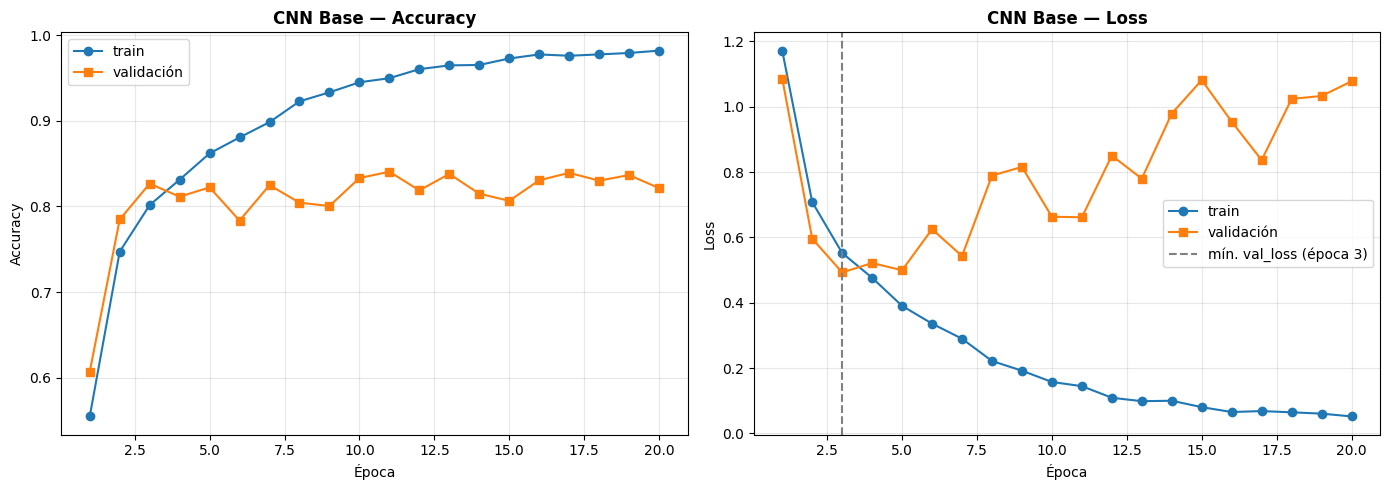

In [18]:
def graficar_historia(historia, titulo):
    h = historia.history
    epocas = range(1, len(h["loss"]) + 1)
    mejor = int(np.argmin(h["val_loss"])) + 1
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    ax[0].plot(epocas, h["accuracy"], "o-", label="train")
    ax[0].plot(epocas, h["val_accuracy"], "s-", label="validación")
    ax[0].set_title(f"{titulo} — Accuracy", fontweight="bold")
    ax[0].set_xlabel("Época"); ax[0].set_ylabel("Accuracy"); ax[0].grid(alpha=.3); ax[0].legend()

    ax[1].plot(epocas, h["loss"], "o-", label="train")
    ax[1].plot(epocas, h["val_loss"], "s-", label="validación")
    ax[1].axvline(mejor, color="gray", ls="--", label=f"mín. val_loss (época {mejor})")
    ax[1].set_title(f"{titulo} — Loss", fontweight="bold")
    ax[1].set_xlabel("Época"); ax[1].set_ylabel("Loss"); ax[1].grid(alpha=.3); ax[1].legend()
    plt.tight_layout(); plt.show()

graficar_historia(historia_base, "CNN Base")

### C.6 Diagnóstico de overfitting (cálculo)
**Qué hace este bloque:**
- Calcula los indicadores que se usan para argumentar el diagnóstico: accuracy final de train y validación, la **brecha** entre ambas, la época donde `val_loss` fue mínima y cuánto subió `val_loss` desde ese mínimo hasta la última época.
- Regla práctica: si el accuracy de train sigue subiendo hacia ~100 % mientras el de validación se estanca y `val_loss` sube, el modelo está **memorizando** el entrenamiento (overfitting).

In [19]:
def diagnostico(historia, nombre):
    h = historia.history
    tr, va = h["accuracy"][-1], h["val_accuracy"][-1]
    ep_min = int(np.argmin(h["val_loss"])) + 1
    vl_min, vl_fin = min(h["val_loss"]), h["val_loss"][-1]
    print(f"===== Diagnóstico {nombre} =====")
    print(f"Accuracy train (última época)  : {tr:.4f}")
    print(f"Accuracy val   (última época)  : {va:.4f}")
    print(f"Mejor accuracy val             : {max(h['val_accuracy']):.4f}")
    print(f"Brecha train - val             : {(tr-va)*100:.2f} puntos porcentuales")
    print(f"Loss train (última época)      : {h['loss'][-1]:.4f}")
    print(f"Época con mínima val_loss      : {ep_min} (val_loss = {vl_min:.4f})")
    print(f"val_loss en la última época    : {vl_fin:.4f} ({(vl_fin/vl_min-1)*100:+.1f} % vs. mínimo)")
    return {"train_acc": tr, "val_acc": va, "best_val_acc": max(h["val_accuracy"]),
            "brecha": tr - va, "epoca_min_val_loss": ep_min, "min_val_loss": vl_min,
            "val_loss_final": vl_fin, "train_loss_final": h["loss"][-1]}

diag_base = diagnostico(historia_base, "CNN Base")

===== Diagnóstico CNN Base =====
Accuracy train (última época)  : 0.9819
Accuracy val   (última época)  : 0.8214
Mejor accuracy val             : 0.8405
Brecha train - val             : 16.06 puntos porcentuales
Loss train (última época)      : 0.0520
Época con mínima val_loss      : 3 (val_loss = 0.4928)
val_loss en la última época    : 1.0778 (+118.7 % vs. mínimo)


### C.6 Diagnóstico de overfitting (párrafo)
> _Completar los valores entre corchetes con lo que imprimió la celda anterior._

La CNN base alcanza un accuracy de entrenamiento de **[train_acc] %** en la última época, mientras que en validación se queda en **[val_acc] %**, es decir, una brecha de **[brecha] puntos porcentuales**. En las curvas se ve que a partir de la época **[época_min_val_loss]** la pérdida de validación deja de bajar y empieza a subir (termina **[x] %** por encima de su mínimo), mientras que la pérdida de entrenamiento sigue cayendo hacia cero. Este patrón (train mejora, validación empeora) es la señal clásica de **overfitting**: la red está memorizando las imágenes de entrenamiento en lugar de aprender rasgos generales de cada tipo de suelo. Las causas principales son: (1) la capa `Dense` posterior al `Flatten`, que concentra la mayoría de los ~1,1 M de parámetros y tiene capacidad de sobra para memorizar; (2) la ausencia total de regularización (sin dropout, sin L2, sin data augmentation); y (3) que la red ve exactamente las mismas imágenes en cada época. Aun así, como EuroSAT tiene más de 20 000 imágenes de entrenamiento, el accuracy de validación es alto; el problema es que deja de mejorar mientras la red sigue memorizando. Esto justifica la CNN mejorada de la Sección D.

## SECCIÓN D — CNN Mejorada (con regularización)

Se aplican **5 técnicas** de regularización (la consigna pide al menos 3):

| Técnica | Dónde | Por qué ayuda |
|---|---|---|
| **Data Augmentation** | Primera capa del modelo | Genera variaciones aleatorias (giros, rotaciones, zoom, contraste) en cada época: el modelo nunca ve la misma imagen dos veces y aprende invariancias reales. |
| **Batch Normalization** | Después de cada `Conv2D`, antes de ReLU | Normaliza las activaciones de cada lote (media 0, varianza 1): estabiliza y acelera el entrenamiento y aporta una ligera regularización. |
| **Dropout** | 0.1 tras cada bloque y 0.3 antes de la salida | Apaga neuronas al azar en entrenamiento, obligando a no depender de unas pocas. |
| **Global Average Pooling (GAP)** | En lugar de `Flatten` | Promedia cada mapa de características en un solo valor: elimina la gran capa densa y reduce drásticamente los parámetros. |
| **Regularización L2** | En los kernels de `Conv2D` y `Dense` | Penaliza pesos grandes en la función de pérdida, favoreciendo modelos más simples. |

### D.1 Data Augmentation y visualización de 4 variaciones
**Qué hace este bloque:**
- Crea un bloque `Sequential` con capas de preprocesamiento de Keras que **solo actúan durante el entrenamiento** (en `predict`/`evaluate` se desactivan solas):
  - `RandomFlip("horizontal_and_vertical")`: espejo horizontal y vertical. En una imagen satelital **no existe “arriba” ni “abajo”**: un bosque o un río reflejados siguen siendo la misma clase. (En fotos normales el giro vertical no tendría sentido; aquí sí.)
  - `RandomRotation(0.25, fill_mode="reflect")`: rota hasta ±90°; el satélite puede captar una autopista o un río en cualquier orientación. El relleno por reflejo evita esquinas negras artificiales.
  - `RandomZoom(0.1)`: acerca/aleja hasta 10 %; simula pequeñas diferencias de escala.
  - `RandomContrast(0.1)`: varía el contraste; simula distinta iluminación, estación del año o bruma atmosférica.
- Se muestran la imagen original y **4 variaciones** generadas con `training=True`.

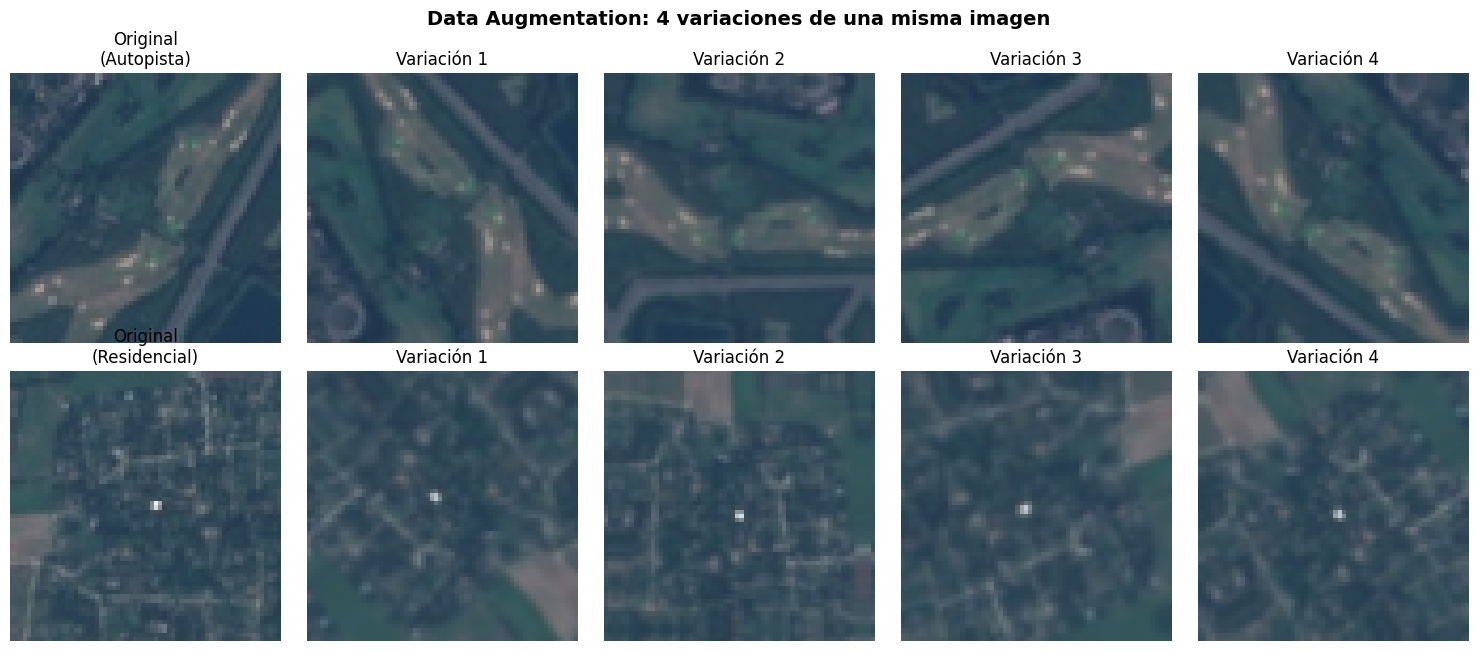

In [20]:
def crear_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.25, fill_mode="reflect"),
        layers.RandomZoom(0.1, fill_mode="reflect"),
        layers.RandomContrast(0.1),
    ], name="data_augmentation")

aug_demo = crear_augmentation()
ejemplos = [int(np.where(y_train == CLASES.index("Autopista"))[0][0]),
            int(np.where(y_train == CLASES.index("Residencial"))[0][0])]

fig, axes = plt.subplots(len(ejemplos), 5, figsize=(15, 3.3*len(ejemplos)))
for fila, idx in enumerate(ejemplos):
    imagen = X_train[idx]
    axes[fila, 0].imshow(imagen); axes[fila, 0].set_title(f"Original\n({CLASES[y_train[idx]]})")
    for i in range(1, 5):
        aumentada = aug_demo(tf.expand_dims(imagen, 0), training=True)[0].numpy()
        axes[fila, i].imshow(np.clip(aumentada, 0, 1))
        axes[fila, i].set_title(f"Variación {i}")
    for a in axes[fila]: a.axis("off")
plt.suptitle("Data Augmentation: 4 variaciones de una misma imagen", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### D.2 Arquitectura de la CNN mejorada
**Qué hace este bloque:**
- `bloque_conv` encapsula un bloque: `Conv2D` (sin sesgo, con L2) → `BatchNormalization` → `ReLU` → `MaxPooling2D` → `Dropout(0.1)`.
  - `use_bias=False` porque BatchNormalization ya incluye un desplazamiento (β) que cumple la función del sesgo.
  - BN se coloca **antes de la activación** para normalizar la entrada de ReLU y evitar que muchas neuronas queden “muertas” (siempre en 0) o con activaciones descontroladas.
  - El Dropout de los bloques es moderado (0.1) porque ya se combina con augmentation, BN y L2; valores muy altos harían que la red **subentrene**.
- La red usa **4 bloques** (32, 64, 128 y 256 filtros); el 4.º bloque permite detectar patrones más complejos ahora que la regularización controla el overfitting. El tamaño baja 64→32→16→8→4.
- `GlobalAveragePooling2D` reemplaza a `Flatten`: convierte el mapa 4×4×256 en un vector de 256 valores (promedio de cada filtro), en vez de 4 096.
- Clasificador: `Dense(128)` con L2 → `Dropout(0.3)` → `Dense(10, softmax)`.
- Se usa la API funcional de Keras y la función recibe el optimizador como parámetro para reutilizarla en la Sección E con SGD, Adam y RMSprop.

In [21]:
L2 = 1e-4   # intensidad de la regularización L2

def bloque_conv(x, filtros):
    x = layers.Conv2D(filtros, (3, 3), padding="same", use_bias=False,
                      kernel_regularizer=regularizers.l2(L2))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.1)(x)
    return x

def crear_cnn_mejorada(optimizador=None, nombre="CNN_Mejorada"):
    entradas = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = crear_augmentation()(entradas)               # 1) Data Augmentation
    for filtros in [32, 64, 128, 256]:               # 2) BN + 3) Dropout + 5) L2
        x = bloque_conv(x, filtros)
    x = layers.GlobalAveragePooling2D()(x)           # 4) GAP en lugar de Flatten
    x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(L2))(x)
    x = layers.Dropout(0.3)(x)
    salidas = layers.Dense(NUM_CLASES, activation="softmax")(x)

    modelo = keras.Model(entradas, salidas, name=nombre)
    modelo.compile(optimizer=optimizador or keras.optimizers.Adam(learning_rate=1e-3),
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modelo

keras.utils.set_random_seed(SEED)
cnn_mejorada = crear_cnn_mejorada()
cnn_mejorada.summary()
params_mejorada = contar_parametros(cnn_mejorada)
print(f"\nReducción de parámetros vs. CNN Base: {(1 - params_mejorada/params_base)*100:.1f} %")

Model: "CNN_Mejorada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             

 Total params: 424,042 (1.62 MB)

 Trainable params: 423,082 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)


Total de parámetros: 424,042
  Conv2D              :      387,936 (91.5 %)
  Dense               :       34,186 (8.1 %)
  BatchNormalization  :        1,920 (0.5 %)

Reducción de parámetros vs. CNN Base: 62.9 %


### D.3 Entrenamiento con callbacks
**Qué hace este bloque:**
- **EarlyStopping** (`monitor='val_loss'`, `patience=8`, `restore_best_weights=True`): si la pérdida de validación no mejora durante 8 épocas seguidas, detiene el entrenamiento y **restaura los pesos de la mejor época**. Evita seguir entrenando cuando ya empezó el overfitting. Se usa paciencia 8 (≥ 5) porque con augmentation la validación oscila de una época a otra.
- **ReduceLROnPlateau** (`factor=0.5`, `patience=3`): si `val_loss` se estanca 3 épocas, reduce la tasa de aprendizaje a la mitad. Pasos más pequeños permiten afinar los pesos cerca de un mínimo.
- Como ReduceLROnPlateau tiene menor paciencia (3) que EarlyStopping (8), primero se intenta bajar el *learning rate* y solo si eso no ayuda se detiene el entrenamiento.
- Se fija un máximo de 40 épocas.

In [22]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                      min_lr=1e-5, verbose=1),
]

inicio = time.time()
historia_mejorada = cnn_mejorada.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_MEJORADA,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=2)
print(f"\nTiempo de entrenamiento: {time.time()-inicio:.1f} s")
print(f"Épocas ejecutadas: {len(historia_mejorada.history['loss'])}")

Epoch 1/40
646/646 - 18s - 28ms/step - accuracy: 0.6405 - loss: 1.0759 - val_accuracy: 0.5678 - val_loss: 1.3181 - learning_rate: 0.0010
Epoch 2/40
646/646 - 11s - 17ms/step - accuracy: 0.7343 - loss: 0.8141 - val_accuracy: 0.7298 - val_loss: 0.8116 - learning_rate: 0.0010
Epoch 3/40
646/646 - 11s - 17ms/step - accuracy: 0.7686 - loss: 0.7308 - val_accuracy: 0.7786 - val_loss: 0.7056 - learning_rate: 0.0010
Epoch 4/40
646/646 - 11s - 17ms/step - accuracy: 0.7907 - loss: 0.6722 - val_accuracy: 0.7525 - val_loss: 0.7421 - learning_rate: 0.0010
Epoch 5/40
646/646 - 11s - 17ms/step - accuracy: 0.8159 - loss: 0.6146 - val_accuracy: 0.8070 - val_loss: 0.6324 - learning_rate: 0.0010
Epoch 6/40
646/646 - 11s - 17ms/step - accuracy: 0.8332 - loss: 0.5679 - val_accuracy: 0.8183 - val_loss: 0.6171 - learning_rate: 0.0010
Epoch 7/40
646/646 - 11s - 17ms/step - accuracy: 0.8459 - loss: 0.5333 - val_accuracy: 0.6340 - val_loss: 1.3013 - learning_rate: 0.0010
Epoch 8/40
646/646 - 11s - 17ms/step - ac

### D.4 Curvas de aprendizaje de la CNN mejorada
**Qué hace este bloque:** reutiliza `graficar_historia` y además grafica cómo cambió la tasa de aprendizaje por efecto de ReduceLROnPlateau (Keras la guarda en `history['learning_rate']` o `history['lr']` según la versión).

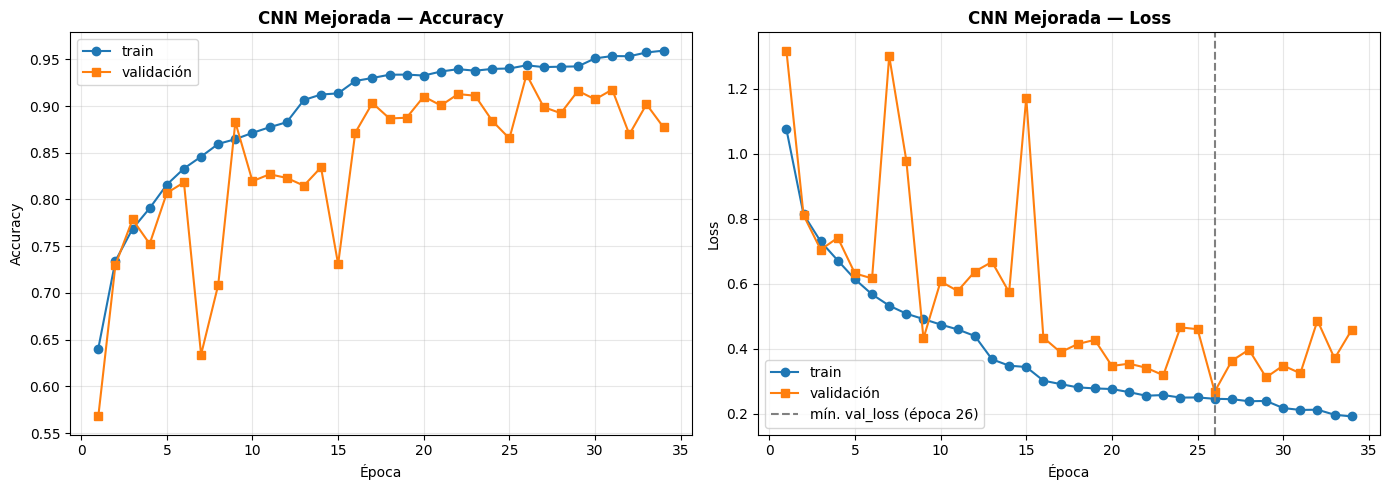

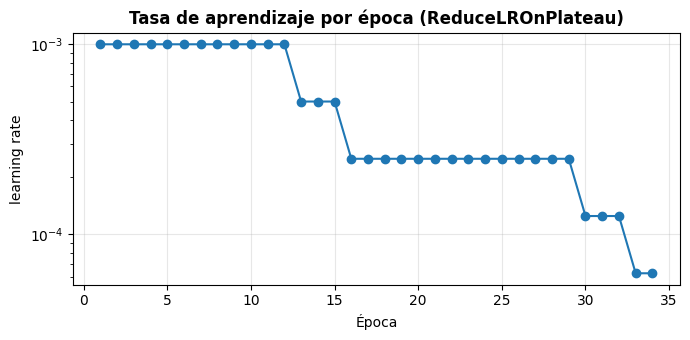

Reducciones del learning rate: 4


In [23]:
graficar_historia(historia_mejorada, "CNN Mejorada")

clave_lr = "learning_rate" if "learning_rate" in historia_mejorada.history else "lr"
if clave_lr in historia_mejorada.history:
    lrs = historia_mejorada.history[clave_lr]
    plt.figure(figsize=(7, 3.5))
    plt.plot(range(1, len(lrs) + 1), lrs, "o-")
    plt.yscale("log"); plt.grid(alpha=.3)
    plt.title("Tasa de aprendizaje por época (ReduceLROnPlateau)", fontweight="bold")
    plt.xlabel("Época"); plt.ylabel("learning rate")
    plt.tight_layout(); plt.show()
    print("Reducciones del learning rate:", int(np.sum(np.diff(lrs) < 0)))

### D.5 Comparación cuantitativa CNN Base vs. CNN Mejorada
**Qué hace este bloque:**
- Ejecuta el mismo diagnóstico de la Sección C sobre la CNN mejorada.
- Evalúa ambos modelos sobre **validación** con `evaluate` (la CNN mejorada ya tiene restaurados sus mejores pesos).
- Arma una tabla comparativa y un gráfico de barras con accuracy de validación y brecha train-val. El test se reserva para la Sección F.

===== Diagnóstico CNN Mejorada =====
Accuracy train (última época)  : 0.9594
Accuracy val   (última época)  : 0.8771
Mejor accuracy val             : 0.9338
Brecha train - val             : 8.23 puntos porcentuales
Loss train (última época)      : 0.1923
Época con mínima val_loss      : 26 (val_loss = 0.2685)
val_loss en la última época    : 0.4591 (+71.0 % vs. mínimo)


,Parámetros,Épocas entrenadas,Acc. train (final),Acc. val (pesos finales),Brecha train-val (pp),Mín. val_loss
CNN Base,1143242,20,0.9819,0.8214,16.0591,0.4928
CNN Mejorada,424042,34,0.9594,0.9338,8.2256,0.2685


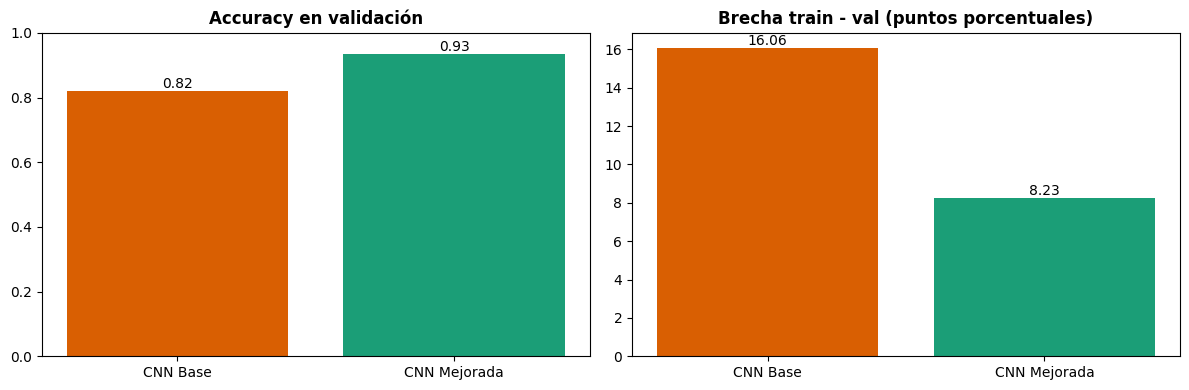

In [24]:
diag_mejorada = diagnostico(historia_mejorada, "CNN Mejorada")

_, acc_val_base = cnn_base.evaluate(X_val, y_val, verbose=0)
_, acc_val_mej  = cnn_mejorada.evaluate(X_val, y_val, verbose=0)

comparacion = pd.DataFrame({
    "Parámetros":               [params_base, params_mejorada],
    "Épocas entrenadas":        [len(historia_base.history["loss"]), len(historia_mejorada.history["loss"])],
    "Acc. train (final)":       [diag_base["train_acc"], diag_mejorada["train_acc"]],
    "Acc. val (pesos finales)": [acc_val_base, acc_val_mej],
    "Brecha train-val (pp)":    [diag_base["brecha"]*100, diag_mejorada["brecha"]*100],
    "Mín. val_loss":            [diag_base["min_val_loss"], diag_mejorada["min_val_loss"]],
}, index=["CNN Base", "CNN Mejorada"])
display(comparacion.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colores = ["#d95f02", "#1b9e77"]
ax[0].bar(comparacion.index, comparacion["Acc. val (pesos finales)"], color=colores)
ax[0].set_title("Accuracy en validación", fontweight="bold"); ax[0].set_ylim(0, 1)
ax[1].bar(comparacion.index, comparacion["Brecha train-val (pp)"], color=colores)
ax[1].set_title("Brecha train - val (puntos porcentuales)", fontweight="bold")
for a in ax:
    for p in a.patches:
        a.annotate(f"{p.get_height():.2f}", (p.get_x()+p.get_width()/2, p.get_height()),
                   ha="center", va="bottom")
plt.tight_layout(); plt.show()

### D.6 Comparación con la CNN Base (párrafo)
> _Completar con los valores de la tabla anterior._

La CNN mejorada **[sí / no] mejoró** el desempeño: el accuracy en validación pasó de **[acc_val_base] %** (CNN Base) a **[acc_val_mej] %**, una diferencia de **[x] puntos**. Más importante aún, el **overfitting se redujo**: la brecha entre train y validación bajó de **[brecha_base] pp** a **[brecha_mej] pp**, y en las curvas ya no se observa la `val_loss` subiendo mientras la de train baja; ambas curvas avanzan juntas (con augmentation es normal que el accuracy de validación quede incluso por encima del de train, porque en train la red ve imágenes deformadas y con dropout activo). Con data augmentation el modelo nunca ve exactamente la misma imagen, por lo que no puede memorizar; Batch Normalization estabilizó el entrenamiento y permitió usar 4 bloques; Dropout y L2 limitaron la dependencia de pesos individuales; y GAP eliminó la gran capa densa, reduciendo los parámetros en **[x] %**. El costo es que la red necesita más épocas para converger (entrenó **[n]** épocas) y ReduceLROnPlateau bajó el *learning rate* **[n] veces**, lo que ayudó a afinar los pesos en la etapa final.

## SECCIÓN E — Comparación de Optimizadores

### E.1 Entrenamiento de la misma arquitectura con SGD, Adam y RMSprop
**Qué hace este bloque:**
- Usa exactamente la misma arquitectura (`crear_cnn_mejorada`) y la misma semilla para los tres optimizadores, de modo que **lo único que cambia es el optimizador**:
  - **SGD con momentum 0.9** (lr = 0.01): actualiza los pesos en la dirección opuesta al gradiente; el momentum acumula la dirección de pasos anteriores para avanzar más rápido y amortiguar oscilaciones. Necesita un lr mayor que los adaptativos.
  - **Adam** (lr = 0.001): combina momentum con una tasa adaptativa por parámetro.
  - **RMSprop** (lr = 0.001): divide el gradiente por la media móvil de su magnitud al cuadrado; adapta el paso, pero sin el término de momentum de primer orden de Adam.
- Se entrenan **15 épocas sin callbacks**, para comparar a todos con el mismo número de épocas y que EarlyStopping no corte a unos antes que a otros.

In [25]:
optimizadores = {
    "SGD (momentum 0.9)": lambda: keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9),
    "Adam":               lambda: keras.optimizers.Adam(learning_rate=1e-3),
    "RMSprop":            lambda: keras.optimizers.RMSprop(learning_rate=1e-3),
}

historias_opt = {}
for nombre, crear_opt in optimizadores.items():
    print(f"\n========== Entrenando con {nombre} ==========")
    keras.utils.set_random_seed(SEED)                 # mismos pesos iniciales para todos
    modelo = crear_cnn_mejorada(optimizador=crear_opt(), nombre="CNN_" + nombre.split()[0])
    inicio = time.time()
    h = modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                   epochs=EPOCHS_OPT, batch_size=BATCH_SIZE, verbose=2)
    historias_opt[nombre] = h.history
    print(f"Tiempo: {time.time()-inicio:.1f} s")


========== Entrenando con SGD (momentum 0.9) ==========
Epoch 1/15
646/646 - 13s - 20ms/step - accuracy: 0.6077 - loss: 1.1605 - val_accuracy: 0.5377 - val_loss: 1.4898
Epoch 2/15
646/646 - 10s - 16ms/step - accuracy: 0.7039 - loss: 0.8852 - val_accuracy: 0.6222 - val_loss: 1.1380
Epoch 3/15
646/646 - 10s - 16ms/step - accuracy: 0.7379 - loss: 0.7939 - val_accuracy: 0.6505 - val_loss: 0.9934
Epoch 4/15
646/646 - 10s - 16ms/step - accuracy: 0.7633 - loss: 0.7351 - val_accuracy: 0.4523 - val_loss: 2.2268
Epoch 5/15
646/646 - 10s - 16ms/step - accuracy: 0.7795 - loss: 0.6914 - val_accuracy: 0.6488 - val_loss: 1.1221
Epoch 6/15
646/646 - 10s - 16ms/step - accuracy: 0.7927 - loss: 0.6560 - val_accuracy: 0.5547 - val_loss: 1.7607
Epoch 7/15
646/646 - 10s - 16ms/step - accuracy: 0.8098 - loss: 0.6140 - val_accuracy: 0.6200 - val_loss: 1.3112
Epoch 8/15
646/646 - 10s - 16ms/step - accuracy: 0.8192 - loss: 0.5794 - val_accuracy: 0.7996 - val_loss: 0.6293
Epoch 9/15
646/646 - 10s - 16ms/step - 

### E.2 val_accuracy de los optimizadores en un mismo gráfico
**Qué hace este bloque:**
- Superpone la curva de `val_accuracy` (izquierda) y `val_loss` (derecha) de los tres optimizadores.
- Calcula una tabla con la **mejor val_accuracy**, la época en que se alcanzó y la **primera época en que cada optimizador supera el 90 % de validación** (indicador de velocidad de convergencia), además de la desviación estándar de `val_accuracy` en las últimas 5 épocas (indicador de estabilidad).

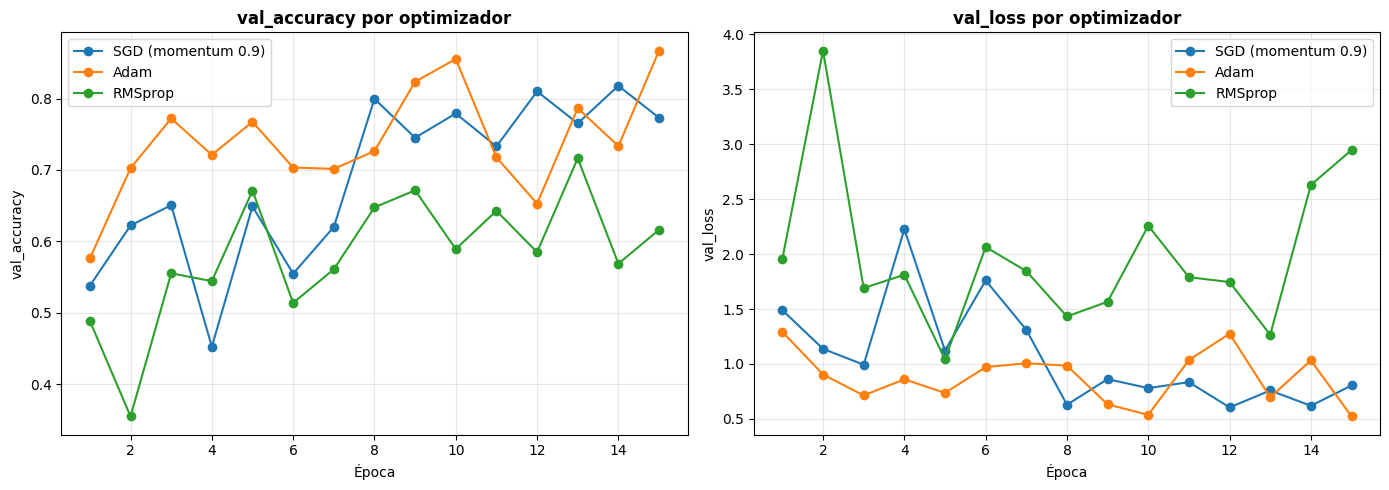

,Mejor val_acc,Época del mejor,1ª época con val_acc ≥ 0.90,val_acc época 1,val_acc final,Desv. val_acc (últ. 5),Acc. train final
Optimizador,,,,,,,
SGD (momentum 0.9),0.8179,14,None,0.5377,0.7730,0.0311,0.8809
Adam,0.8671,15,None,0.5760,0.8671,0.0719,0.8944
RMSprop,0.7163,13,None,0.4885,0.6161,0.0520,0.8847


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for nombre, h in historias_opt.items():
    ep = range(1, len(h["val_accuracy"]) + 1)
    ax[0].plot(ep, h["val_accuracy"], "o-", label=nombre)
    ax[1].plot(ep, h["val_loss"], "o-", label=nombre)
ax[0].set_title("val_accuracy por optimizador", fontweight="bold")
ax[0].set_xlabel("Época"); ax[0].set_ylabel("val_accuracy"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].set_title("val_loss por optimizador", fontweight="bold")
ax[1].set_xlabel("Época"); ax[1].set_ylabel("val_loss"); ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.show()

filas = []
for nombre, h in historias_opt.items():
    va = np.array(h["val_accuracy"])
    filas.append({
        "Optimizador": nombre,
        "Mejor val_acc": va.max(),
        "Época del mejor": int(va.argmax()) + 1,
        "1ª época con val_acc ≥ 0.90": (int(np.argmax(va >= 0.90)) + 1) if (va >= 0.90).any() else None,
        "val_acc época 1": va[0],
        "val_acc final": va[-1],
        "Desv. val_acc (últ. 5)": va[-5:].std(),
        "Acc. train final": h["accuracy"][-1],
    })
tabla_opt = pd.DataFrame(filas).set_index("Optimizador")
display(tabla_opt.round(4))

### E.3 Análisis de optimizadores (párrafo)
> _Completar con los valores de la tabla anterior._

En las curvas de `val_accuracy`, **[optimizador más rápido]** es el que **converge más rápido**: supera el 90 % de validación en la época **[n]**, mientras que **[otro]** lo hace en la época **[n]**. El **mejor resultado** en validación lo alcanza **[optimizador]** con **[x] %**. Adam y RMSprop, al adaptar la tasa de aprendizaje de cada peso, avanzan rápido en las primeras épocas sin necesidad de ajustar mucho el lr; RMSprop suele mostrar una curva de validación más irregular porque no suaviza la dirección del gradiente con momentum de primer orden (ver la columna “Desv. val_acc (últ. 5)”). SGD con momentum arranca más lento y con más oscilación al inicio por su lr fijo de 0.01, pero es muy competitivo cuando se entrena más épocas y con reducción de lr, y a menudo generaliza bien. Con el presupuesto de 15 épocas, **[optimizador]** ofrece el mejor balance entre velocidad y resultado, lo que **[confirma / no confirma]** la elección de Adam para la CNN mejorada.

## SECCIÓN F — Evaluación Rigurosa (sobre test)

### F.1 Accuracy global en test con la CNN Mejorada
**Qué hace este bloque:**
- Por primera vez se usan las imágenes de **test** (15 % reservado al inicio, nunca vistas en entrenamiento ni en la selección de modelos), por lo que esta es una estimación honesta del desempeño real.
- `predict` devuelve una matriz de probabilidades `(n_test, 10)`; `argmax` toma la clase con mayor probabilidad como predicción.
- También se evalúa la CNN Base en test como referencia.

In [27]:
y_proba = cnn_mejorada.predict(X_test, verbose=0)    # probabilidades por clase
y_pred  = np.argmax(y_proba, axis=1)                 # clase predicha

loss_test, acc_test = cnn_mejorada.evaluate(X_test, y_test, verbose=0)
_, acc_test_base = cnn_base.evaluate(X_test, y_test, verbose=0)

print(f"Imágenes de test           : {len(X_test)}")
print(f"Accuracy test CNN Mejorada : {acc_test:.4f}  ({acc_test*100:.2f} %)")
print(f"Loss test CNN Mejorada     : {loss_test:.4f}")
print(f"Accuracy test CNN Base     : {acc_test_base:.4f}  ({acc_test_base*100:.2f} %)  <- referencia")

Imágenes de test           : 4050
Accuracy test CNN Mejorada : 0.9393  (93.93 %)
Loss test CNN Mejorada     : 0.2540
Accuracy test CNN Base     : 0.8316  (83.16 %)  <- referencia


### F.2 Classification report (precision, recall y F1 por clase)
**Qué hace este bloque:**
- **Precision** de una clase: de todas las imágenes que el modelo dijo que eran de esa clase, qué porcentaje lo era realmente.
- **Recall**: de todas las imágenes que realmente eran de esa clase, qué porcentaje encontró el modelo.
- **F1-score**: media armónica de precision y recall; resume ambas en un número.
- `support` es el número de imágenes reales de cada clase en test. Se ordena por F1 para identificar la mejor y la peor clase.

In [28]:
print(classification_report(y_test, y_pred, target_names=CLASES, digits=4))

reporte = pd.DataFrame(classification_report(y_test, y_pred, target_names=CLASES,
                                             output_dict=True)).T.loc[CLASES]
reporte = reporte.sort_values("f1-score", ascending=False)
print("Mejor clase (F1):", reporte.index[0],  f"-> {reporte['f1-score'].iloc[0]:.4f}")
print("Peor clase  (F1):", reporte.index[-1], f"-> {reporte['f1-score'].iloc[-1]:.4f}")

               precision    recall  f1-score   support

Cultivo anual     0.9212    0.9356    0.9283       450
       Bosque     0.9335    0.9978    0.9646       450
Veg. herbácea     0.9109    0.9311    0.9209       450
    Autopista     0.9542    0.9440    0.9491       375
   Industrial     0.9969    0.8453    0.9149       375
     Pastizal     0.9521    0.9267    0.9392       300
Cultivo perm.     0.9210    0.9013    0.9111       375
  Residencial     0.8804    0.9978    0.9354       450
          Río     0.9637    0.9200    0.9413       375
     Lago/mar     0.9954    0.9644    0.9797       450

     accuracy                         0.9393      4050
    macro avg     0.9429    0.9364    0.9384      4050
 weighted avg     0.9414    0.9393    0.9391      4050

Mejor clase (F1): Lago/mar -> 0.9797
Peor clase  (F1): Cultivo perm. -> 0.9111


### F.3 Matriz de confusión con heatmap
**Qué hace este bloque:**
- `confusion_matrix` cuenta, para cada clase real (filas), cuántas imágenes se predijeron como cada clase (columnas). La diagonal son los aciertos.
- Se dibujan dos heatmaps con `seaborn`: con **conteos absolutos** y **normalizada por fila** (cada fila suma 1, así la diagonal es el recall de cada clase y se comparan clases de distinto tamaño).

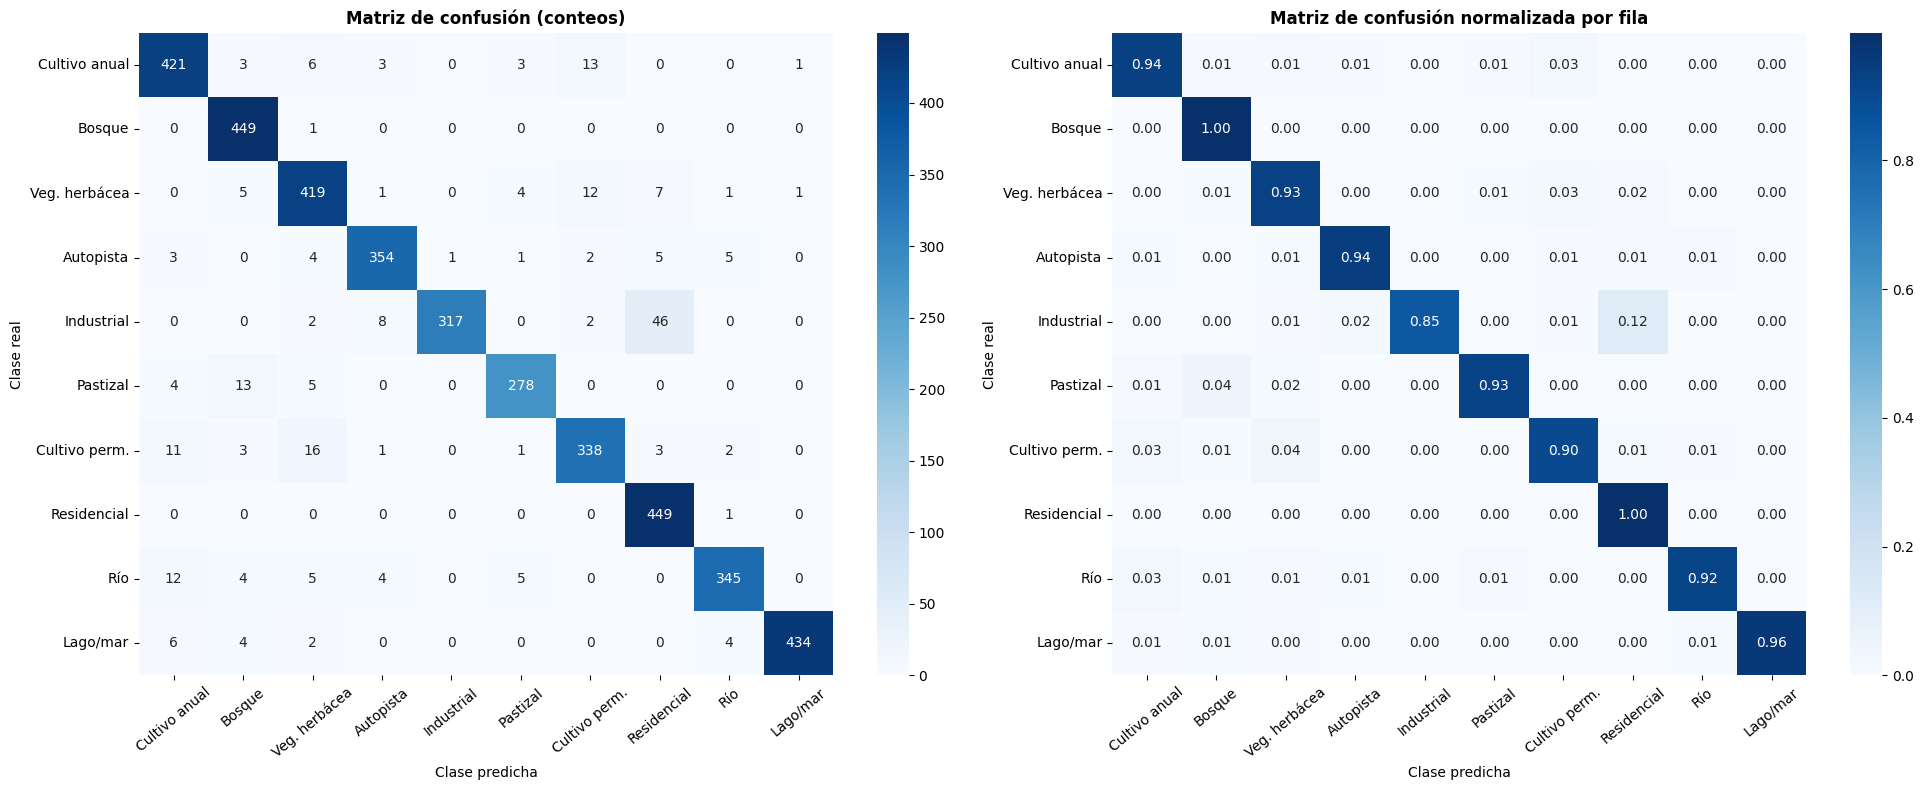

In [29]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=ax[0])
ax[0].set_title("Matriz de confusión (conteos)", fontweight="bold")
ax[0].set_xlabel("Clase predicha"); ax[0].set_ylabel("Clase real")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=ax[1])
ax[1].set_title("Matriz de confusión normalizada por fila", fontweight="bold")
ax[1].set_xlabel("Clase predicha"); ax[1].set_ylabel("Clase real")
for a in ax:
    a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

### F.4 Curvas ROC por clase (One-vs-Rest) con AUC
**Qué hace este bloque:**
- La curva ROC es para problemas binarios, así que se aplica la estrategia **One-vs-Rest**: para cada clase se considera “esa clase” como positiva y “todas las demás” como negativa.
- `label_binarize` convierte las etiquetas a formato one-hot; con la probabilidad que el modelo asigna a cada clase, `roc_curve` calcula la tasa de verdaderos positivos (TPR) frente a la de falsos positivos (FPR) para todos los umbrales.
- **AUC** (área bajo la curva): 1.0 es perfecto y 0.5 equivale a adivinar al azar (diagonal punteada). También se reporta el AUC **macro** (promedio simple de las clases).
- Como los AUC de este problema son muy cercanos a 1, se agrega un zoom de la esquina superior izquierda para poder distinguir las curvas.

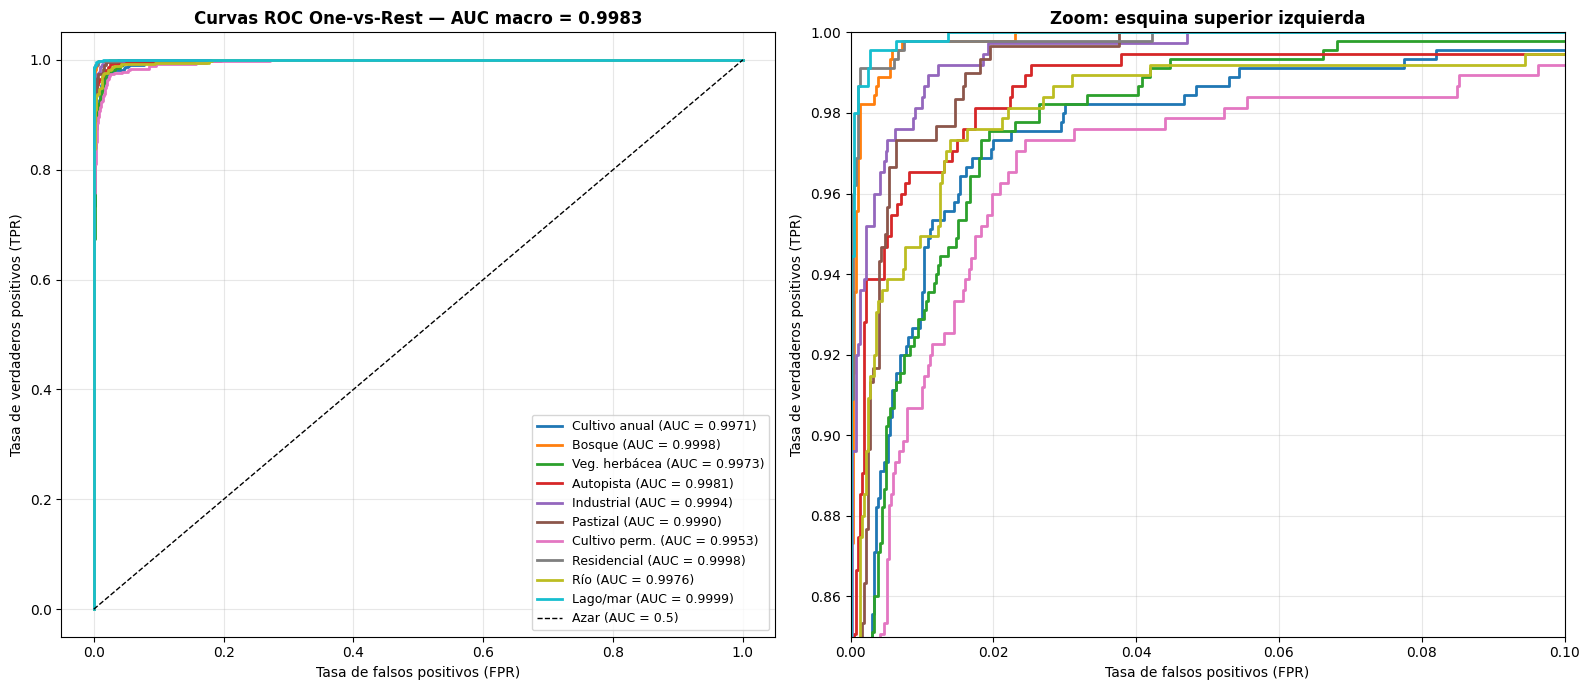

Lago/mar         0.9999
Residencial      0.9998
Bosque           0.9998
Industrial       0.9994
Pastizal         0.9990
Autopista        0.9981
Río              0.9976
Veg. herbácea    0.9973
Cultivo anual    0.9971
Cultivo perm.    0.9953
Name: AUC, dtype: float64

AUC macro: 0.9983


In [30]:
y_test_bin = label_binarize(y_test, classes=range(NUM_CLASES))
colores_roc = sns.color_palette("tab10", NUM_CLASES)

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
auc_por_clase = {}
for i, clase in enumerate(CLASES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_por_clase[clase] = auc(fpr, tpr)
    for a in ax:
        a.plot(fpr, tpr, lw=2, color=colores_roc[i], label=f"{clase} (AUC = {auc_por_clase[clase]:.4f})")
auc_macro = np.mean(list(auc_por_clase.values()))
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5)")
ax[0].set_title(f"Curvas ROC One-vs-Rest — AUC macro = {auc_macro:.4f}", fontweight="bold")
ax[1].set_xlim(0, 0.10); ax[1].set_ylim(0.85, 1.0)
ax[1].set_title("Zoom: esquina superior izquierda", fontweight="bold")
for a in ax:
    a.set_xlabel("Tasa de falsos positivos (FPR)"); a.set_ylabel("Tasa de verdaderos positivos (TPR)")
    a.grid(alpha=.3)
ax[0].legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

print(pd.Series(auc_por_clase, name="AUC").sort_values(ascending=False).round(4))
print(f"\nAUC macro: {auc_macro:.4f}")

### F.5 Las 3 confusiones más frecuentes
**Qué hace este bloque:**
- Copia la matriz de confusión, pone la diagonal en 0 (los aciertos no interesan aquí) y ordena las celdas restantes de mayor a menor.
- Imprime los 3 pares (clase real → clase predicha) con más errores, junto con el porcentaje de la clase real que representan, y muestra ejemplos de imágenes de cada confusión para justificar la explicación con evidencia visual.

Top 3 confusiones (real -> predicha):
  1.     Industrial -> Residencial   : 46 imágenes (12.3 % de las imágenes de Industrial en test)
  2.  Cultivo perm. -> Veg. herbácea : 16 imágenes (4.3 % de las imágenes de Cultivo perm. en test)
  3.       Pastizal -> Bosque        : 13 imágenes (4.3 % de las imágenes de Pastizal en test)


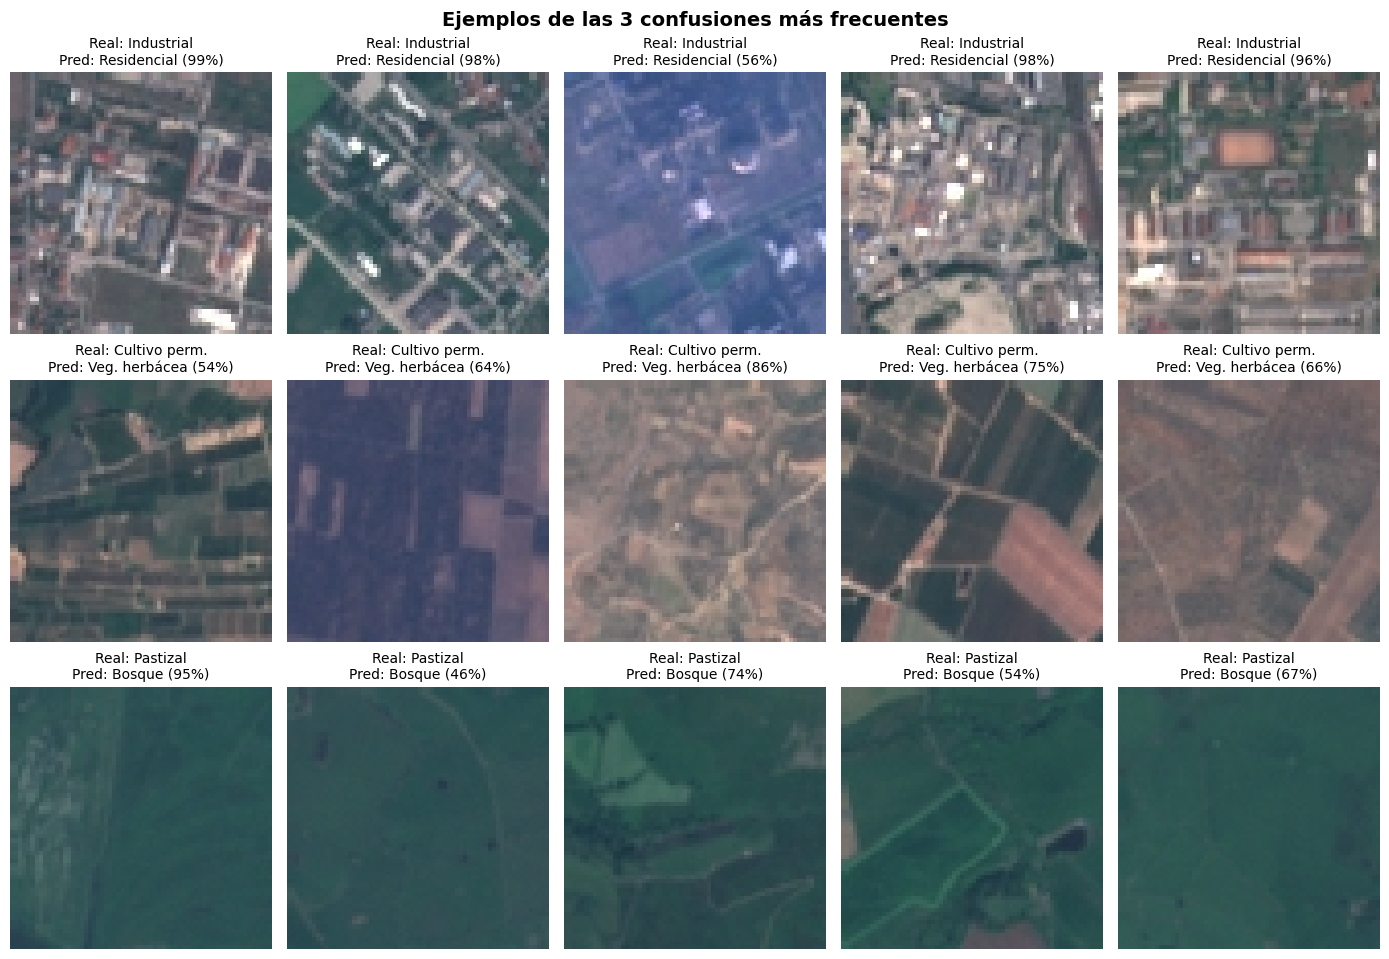

In [31]:
errores = cm.copy()
np.fill_diagonal(errores, 0)
orden = np.dstack(np.unravel_index(np.argsort(errores.ravel(), kind="stable")[::-1], errores.shape))[0]
top3 = [(int(r), int(p)) for r, p in orden if errores[r, p] > 0][:3]

print("Top 3 confusiones (real -> predicha):")
for k, (r, p) in enumerate(top3, 1):
    print(f"  {k}. {CLASES[r]:>14s} -> {CLASES[p]:<14s}: {errores[r, p]} imágenes "
          f"({errores[r, p]/cm[r].sum()*100:.1f} % de las imágenes de {CLASES[r]} en test)")

# Hasta 5 ejemplos de cada confusión
fig, axes = plt.subplots(len(top3), 5, figsize=(14, 3.3*len(top3)), squeeze=False)
for fila, (r, p) in enumerate(top3):
    idx = np.where((y_test == r) & (y_pred == p))[0][:5]
    for col in range(5):
        ax = axes[fila, col]; ax.axis("off")
        if col < len(idx):
            ax.imshow(X_test[idx[col]])
            ax.set_title(f"Real: {CLASES[r]}\nPred: {CLASES[p]} ({y_proba[idx[col], p]*100:.0f}%)", fontsize=10)
plt.suptitle("Ejemplos de las 3 confusiones más frecuentes", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### F.5 Explicación de las confusiones (párrafo)
> _Ajustar a los pares que salgan en tu ejecución; abajo se explican los más habituales en EuroSAT._

- **Cultivo permanente ↔ Vegetación herbácea / Cultivo anual:** las tres clases son parches de vegetación con colores verdes y marrones casi idénticos (ver B.6b). El cultivo permanente (viñedos, olivares, frutales) se distingue por hileras finas y regulares que a 10 m por píxel ocupan 1–2 píxeles, así que muchas veces no se ven y la parcela parece pasto o un cultivo anual.
- **Pastizal ↔ Vegetación herbácea / Bosque:** el pastizal es una superficie verde y homogénea; la vegetación herbácea es casi lo mismo pero más irregular, y un pastizal oscuro o con arbustos se parece al borde de un bosque.
- **Autopista ↔ Río (y Autopista ↔ Residencial / Industrial):** autopistas y ríos son ambas **estructuras lineales** que cruzan la imagen; un río estrecho o con aguas turbias se ve como una franja gris oscura igual que el asfalto. Además, las autopistas suelen pasar junto a zonas urbanas, por lo que la imagen contiene casas o naves industriales y la red se guía por ellas.
- **Industrial ↔ Residencial:** ambas son texturas de edificaciones con techos claros; se diferencian por el tamaño de los techos (naves grandes vs. casas pequeñas), algo difícil de ver a 64×64.

En general, los errores ocurren entre clases con **color y textura similares** o en imágenes que **mezclan dos usos de suelo** (por ejemplo, un río que pasa junto a cultivos). No son errores absurdos: incluso para una persona sería difícil decidir la etiqueta en varias de esas imágenes.

### F.6 Análisis de errores visual (≥ 10 imágenes mal clasificadas)
**Qué hace este bloque:**
- Selecciona las imágenes de test mal clasificadas y las ordena por la **confianza** con la que el modelo se equivocó (probabilidad de la clase predicha), mostrando primero los errores “más seguros”.
- Dibuja 15 en una grilla de 3×5 con su clase real (verde), la predicha (rojo) y la confianza. Esto permite ver patrones: imágenes que mezclan dos usos de suelo, parcelas sin textura visible, nubes o bruma, o etiquetas dudosas.

Imágenes mal clasificadas: 246 de 4050 (6.1 %)


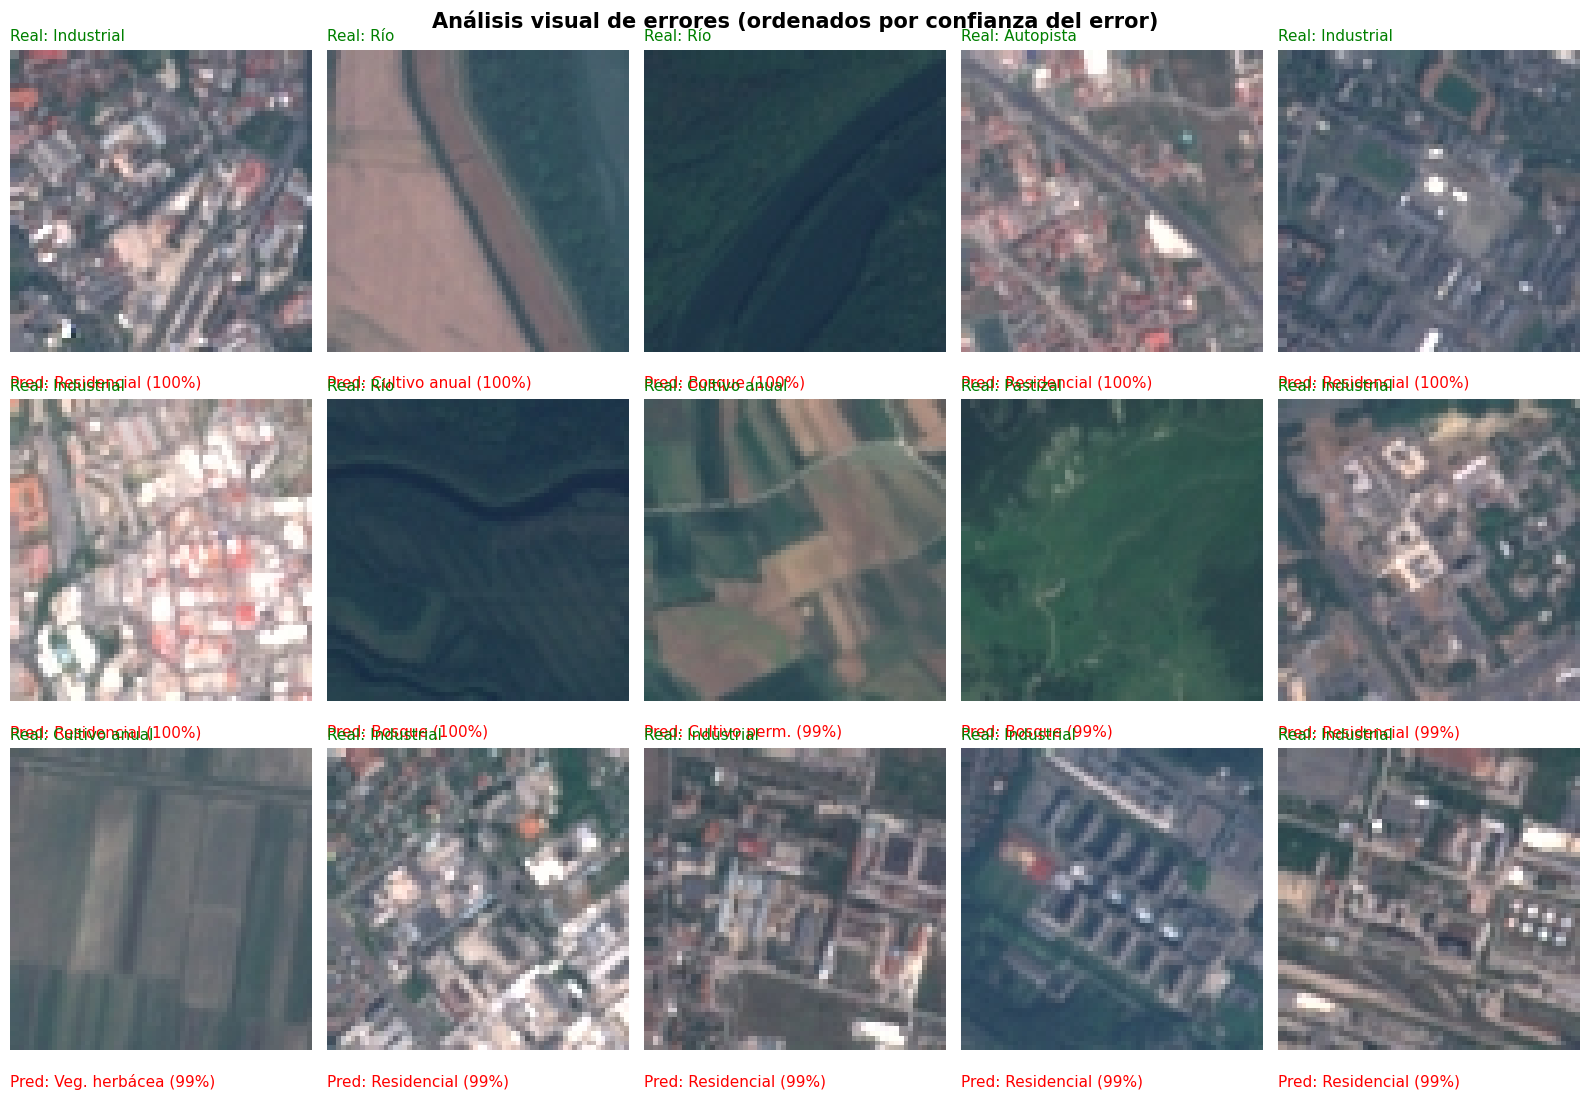

In [35]:
mal = np.where(y_pred != y_test)[0]
print(f"Imágenes mal clasificadas: {len(mal)} de {len(y_test)} ({len(mal)/len(y_test)*100:.1f} %)")
mal = mal[np.argsort(-y_proba[mal, y_pred[mal]])]   # ordenar por confianza del error

n = min(15, len(mal))
fig, axes = plt.subplots(3, 5, figsize=(16, 11))
for k, ax in enumerate(axes.ravel()):
    ax.axis("off")
    if k < n:
        i = mal[k]
        ax.imshow(X_test[i])
        ax.set_title(f"Real: {CLASES[y_test[i]]}", color="green", fontsize=11, loc="left")
        ax.text(0.0, -0.08, f"Pred: {CLASES[y_pred[i]]} ({y_proba[i, y_pred[i]]*100:.0f}%)",
                color="red", fontsize=11, transform=ax.transAxes, va="top")
plt.suptitle("Análisis visual de errores (ordenados por confianza del error)", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

### F.7 Guardar y recargar el modelo final
**Qué hace este bloque:** guarda la CNN mejorada en el formato nativo de Keras (`.keras`) para poder cargarla después con `keras.models.load_model` sin reentrenar, y la vuelve a cargar para comprobar que predice lo mismo.

In [33]:
cnn_mejorada.save("cnn_mejorada_eurosat.keras")
modelo_cargado = keras.models.load_model("cnn_mejorada_eurosat.keras")
iguales = np.array_equal(np.argmax(modelo_cargado.predict(X_test[:50], verbose=0), axis=1), y_pred[:50])
print("Modelo guardado y recargado correctamente. Predicciones idénticas:", iguales)

Modelo guardado y recargado correctamente. Predicciones idénticas: True


### F.8 Resumen numérico de todos los resultados
**Qué hace este bloque:** reúne en un solo diccionario las cifras clave del notebook (las que se citan en los párrafos de análisis y en las conclusiones), para tenerlas a la vista en la defensa.

In [34]:
resultados = {
    "params_base": int(params_base), "params_mejorada": int(params_mejorada),
    "base": {k: round(float(v), 4) for k, v in diag_base.items()},
    "mejorada": {k: round(float(v), 4) for k, v in diag_mejorada.items()},
    "epocas_mejorada": len(historia_mejorada.history["loss"]),
    "acc_val_base": round(float(acc_val_base), 4), "acc_val_mejorada": round(float(acc_val_mej), 4),
    "acc_test_base": round(float(acc_test_base), 4), "acc_test_mejorada": round(float(acc_test), 4),
    "loss_test_mejorada": round(float(loss_test), 4),
    "auc_macro": round(float(auc_macro), 4),
    "auc_por_clase": {k: round(float(v), 4) for k, v in auc_por_clase.items()},
    "f1_por_clase": reporte["f1-score"].round(4).to_dict(),
    "top3_confusiones": [(CLASES[r], CLASES[p], int(errores[r, p])) for r, p in top3],
    "optimizadores": tabla_opt.round(4).reset_index().to_dict(orient="records"),
    "errores_test": int(len(mal)),
}
print(json.dumps(resultados, indent=2, ensure_ascii=False))

{
  "params_base": 1143242,
  "params_mejorada": 424042,
  "base": {
    "train_acc": 0.9819,
    "val_acc": 0.8214,
    "best_val_acc": 0.8405,
    "brecha": 0.1606,
    "epoca_min_val_loss": 3.0,
    "min_val_loss": 0.4928,
    "val_loss_final": 1.0778,
    "train_loss_final": 0.052
  },
  "mejorada": {
    "train_acc": 0.9594,
    "val_acc": 0.8771,
    "best_val_acc": 0.9338,
    "brecha": 0.0823,
    "epoca_min_val_loss": 26.0,
    "min_val_loss": 0.2685,
    "val_loss_final": 0.4591,
    "train_loss_final": 0.1923
  },
  "epocas_mejorada": 34,
  "acc_val_base": 0.8214,
  "acc_val_mejorada": 0.9338,
  "acc_test_base": 0.8316,
  "acc_test_mejorada": 0.9393,
  "loss_test_mejorada": 0.254,
  "auc_macro": 0.9983,
  "auc_por_clase": {
    "Cultivo anual": 0.9971,
    "Bosque": 0.9998,
    "Veg. herbácea": 0.9973,
    "Autopista": 0.9981,
    "Industrial": 0.9994,
    "Pastizal": 0.999,
    "Cultivo perm.": 0.9953,
    "Residencial": 0.9998,
    "Río": 0.9976,
    "Lago/mar": 0.9999
  }

## SECCIÓN G — Conclusiones
> _Reemplazar los valores entre corchetes con los resultados de tu ejecución (la celda F.8 los reúne todos)._

**1. Resumen de resultados.** La CNN mejorada alcanzó un **accuracy de [acc_test] % en test** (frente a **[acc_test_base] %** de la CNN base), con un AUC macro One-vs-Rest de **[auc_macro]**. La mejor clase fue **[mejor clase]** (F1 = [x]) y la peor **[peor clase]** (F1 = [x]). Las clases con apariencia muy característica (Bosque, Lago/mar, Residencial, Industrial) suelen ser las más fáciles; las agrícolas y la autopista, las más difíciles.

**2. Impacto de la regularización.** La CNN base memorizó el entrenamiento (train ≈ [x] % vs. val ≈ [x] %, brecha de [x] pp, `val_loss` creciente desde la época [n]). Con data augmentation, Batch Normalization, Dropout, GAP y L2, la brecha bajó a **[x] pp**, la validación cambió **[x] puntos** y el modelo usó **[x] % menos parámetros**. La regularización no solo redujo el overfitting sino que [mejoró / mantuvo] el resultado final con un modelo mucho más pequeño.

**3. Confusiones más frecuentes.** Las tres confusiones principales fueron **[par 1]**, **[par 2]** y **[par 3]**. Se explican por similitud visual: parches de vegetación con colores casi iguales (cultivos, pastizal, vegetación herbácea), estructuras lineales parecidas (autopista y río) y texturas de edificaciones (industrial y residencial), agravadas por la baja resolución (64×64 a 10 m por píxel) y por imágenes que mezclan dos usos de suelo.

**4. Lecciones aprendidas.**
- Una CNN sin regularización puede llegar a ~100 % en train y aun así dejar de mejorar en validación; las curvas train/val son imprescindibles para detectarlo.
- La mayoría de parámetros de una CNN clásica está en la capa densa tras `Flatten`; GAP reduce el modelo y el overfitting a la vez.
- La data augmentation debe elegirse según el dominio: en imágenes satelitales los giros verticales y las rotaciones de 90° son válidos porque no existe “arriba”, cosa que no ocurre en fotos normales.
- Los callbacks (EarlyStopping + ReduceLROnPlateau) automatizan cuándo parar y cuándo afinar, y evitan elegir el número de épocas a mano.
- El optimizador cambia la velocidad de convergencia: Adam/RMSprop avanzan más rápido al inicio; SGD necesita más épocas o ajuste del lr.
- El accuracy global no basta: el classification report y la matriz de confusión revelan qué clases fallan y por qué.

**5. Limitaciones y posibles mejoras.**
- *Limitaciones:* solo se usaron las 3 bandas RGB, cuando Sentinel-2 ofrece 13 bandas (por ejemplo, el infrarrojo cercano distingue muy bien tipos de vegetación); resolución de 64×64 a 10 m/píxel, que borra detalles como hileras de cultivo; todas las imágenes son de Europa, por lo que el modelo podría no generalizar a otros paisajes (por ejemplo, Perú); y un solo split train/val/test (los resultados pueden variar unos puntos con otra semilla).
- *Mejoras:* **transfer learning** con un modelo preentrenado en ImageNet (p. ej. EfficientNetB0 o ResNet50), que en EuroSAT supera el 98 %; usar la versión multiespectral (`eurosat/all`) con las 13 bandas; augmentation más rica (brillo, MixUp/CutMix); validación cruzada; y búsqueda de hiperparámetros (lr, dropout, L2) con KerasTuner.